# Deliverable 2 : Image denoising with a convolutional autoencoder (TensorFlow / Keras)

**Author**:

| Name | Email |
|---|---|
| Zakarya Zitouni | zakarya.zitouni@viacesi.fr |

**Context.** TouNum digitises photographs in bulk, and noisy scans degrade the downstream models: the photo classifier of Deliverable 1 and the captioning model of Deliverable 3. This notebook delivers the denoising step of the chain D1 → D2 → D3.

**Data.** COCO 2017. `train2017` (118,287 images) is used for training and `val2017` (5,000) for every model-selection decision. A fixed random subset of `test2017` (40,670 images) is kept for the final evaluation. Annotations are not used.

**Method.** Clean images are corrupted with four synthetic noise models, and a blind convolutional autoencoder learns the inverse mapping. Quality is measured with PSNR and SSIM. A frozen InceptionV3, the usual captioning encoder, also measures how closely it represents the denoised image compared with the clean one. The baselines are Gaussian and median filters tuned on validation, and the autoencoder of the Image Processing workshop.

**Brief items.** File loading: Section 2. Denoising code: Sections 5 to 10, 12 and 13. Case study (noise removed versus detail lost): Section 11.

**Beyond the brief.** We added analyses that the brief does not require, each because a result would otherwise be unverified or unusable downstream. Each is marked where it appears:
* data integrity: duplicate and leakage removal (Section 2) and a check that the targets are clean (Section 3);
* optimistic baselines, with filters tuned per condition (Section 7), and extrapolation beyond the training noise (Section 11.6);
* **E1**, statistical significance of the differences between methods;
* **E2**, a check that clean inputs pass through unchanged;
* **E3**, whether the content needed for captioning (Deliverable 3) survives denoising;
* a fine-tuning stage (Section 13) for noise shared across the colour channels and for JPEG compression, found when the whole chain was tested on real files. The delivered model, `denoiser_coco_v2.keras`, comes from this stage.

## Section 1 - Setup and configuration

All hyper-parameters are defined in the cell below. Every random draw (splits, crops, noise, weight initialisation) derives from `SEED`, so the evaluation images and their noise are identical across runs.

In [1]:
import hashlib, io, json, math, os, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
for gpu in tf.config.list_physical_devices("GPU"):          # hard cap: leaves GPU memory for the display driver
    tf.config.set_logical_device_configuration(gpu, [tf.config.LogicalDeviceConfiguration(memory_limit=5000)])

# ---------------- SETTINGS ----------------
DATA_DIR  = Path(os.environ.get("COCO_DIR", "coco2017"))   # contains train2017/, val2017/, test2017/
SPLITS    = {"train": DATA_DIR / "train2017", "val": DATA_DIR / "val2017", "test": DATA_DIR / "test2017"}
CACHE_DIR = Path("cache")                      # file inventory and noise estimates (recomputed if absent)

PATCH        = 128     # training crop size
EVAL_SIZE    = 256     # evaluation crop size (centre crop)
MIN_SIDE     = 256     # images with a shorter side are upscaled to it (aspect ratio kept)
BATCH_SIZE   = 16
STEPS_PER_EPOCH = 1000
STEP_EPOCHS     = 6        # common budget of the four design steps (Section 9)
FINAL_EPOCHS    = 60       # budget of the final model (Section 9)
LEARNING_RATE     = 1e-3   # peak of the cosine schedule, models with batch normalisation
RES_LEARNING_RATE = 2e-4   # peak for the residual-block U-Net (no normalisation layer; diverges at 1e-3)
BASE_FILTERS    = 32      # BN U-Net (steps 2-3): filters of the first level, doubled at each level
DEPTH           = 4       # BN U-Net: number of 2x2 poolings
RES_FILTERS     = 64      # final residual-block U-Net: filters of the first level, doubled at each level
RES_DEPTH       = 3       # final model: number of stride-2 down-samplings, inputs must be multiples of 2**RES_DEPTH = 8
RES_BLOCKS      = 4       # final model: residual blocks per level

N_VAL_MONITOR = 300    # validation crops used for early stopping
N_VAL_SCORE   = 500   # validation crops used to score the design steps
N_VAL_TUNE    = 200    # validation crops used to tune the filters
N_TEST        = 1000   # fixed random subset of test2017 used for the final evaluation
N_NOISE_PROBE = 2000   # images per split for the noise estimate (Section 3)

PARALLEL_CALLS = 6       # images decoded in parallel (bounds host memory)
MODEL_PATH   = CACHE_DIR / "denoiser_coco.keras"          # first-stage model (Section 9), the starting point of Section 13
HISTORY_PATH = CACHE_DIR / "denoiser_coco_history.json"   # its training curves
FT_EPOCHS        = 15                                   # fine-tuning on correlated and compressed noise (Section 13)
FT_LEARNING_RATE = 5e-5                                 # a quarter of RES_LEARNING_RATE: adaptation, not retraining
P_JPEG, JPEG_Q   = 0.5, (30, 95)                         # share of JPEG-compressed training inputs, and their quality range
FINAL_PATH       = Path("denoiser_coco_v2.keras")        # the delivered model
FT_RESULTS_PATH  = Path("denoiser_coco_v2_results.json") # its training curves and its comparison with the first stage
SEED = 42
# ------------------------------------------

keras.utils.set_random_seed(SEED)
CACHE_DIR.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
for name, d in SPLITS.items():
    print(f"{name:<5} {d}  exists: {d.exists()}")

I0000 00:00:1793825959.920437  192641 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793825961.051744  192641 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1
train /home/zakar/tf-cache/coco_local/train2017  exists: True
val   /home/zakar/tf-cache/coco_local/val2017  exists: True
test  /home/zakar/tf-cache/coco_local/test2017  exists: True


## Section 2 - File loading (deliverable item 1)

Every file is inventoried from its header (size, colour mode), and the inventory is cached in `CACHE_DIR`. Exact duplicates (same size and MD5) are removed within splits, and from training when they also appear in validation or test. `decode()` is the single image reader: it returns RGB in [0, 1], replicates grayscale images, and upscales images whose shorter side is below `MIN_SIDE`.

*Beyond the brief:* the duplicate check. COCO contains a few identical files across splits; a test image left in the training set would inflate the test scores.

In [2]:
def file_record(split, path):
    with Image.open(path) as im:
        width, height, mode = im.size[0], im.size[1], im.mode
    with open(path, "rb") as f:
        head = hashlib.md5(f.read(1 << 14)).hexdigest()
    return {"split": split, "path": str(path), "width": width, "height": height, "mode": mode,
            "bytes": path.stat().st_size, "head_md5": head}


inventory_file = CACHE_DIR / "inventory.csv"
if inventory_file.exists():
    inventory = pd.read_csv(inventory_file)
else:
    jobs = [(s, p) for s, d in SPLITS.items() for p in sorted(d.iterdir()) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    with ThreadPoolExecutor(8) as pool:
        inventory = pd.DataFrame(pool.map(lambda job: file_record(*job), jobs))
    inventory.to_csv(inventory_file, index=False)

inventory["short_side"] = inventory[["width", "height"]].min(axis=1)
summary_rows = []
for split, g in inventory.groupby("split", sort=False):
    summary_rows.append({"split": split, "images": len(g), "total size (GB)": g.bytes.sum() / 1e9,
                         "median width": g.width.median(), "median height": g.height.median(),
                         "min short side": g.short_side.min(), f"short side < {MIN_SIDE}": int((g.short_side < MIN_SIDE).sum()),
                         "grayscale (L)": int((g["mode"] == "L").sum()), "other modes": int((~g["mode"].isin(["RGB", "L"])).sum())})
display(pd.DataFrame(summary_rows).set_index("split").round(2))
print("Colour modes:", inventory["mode"].value_counts().to_dict())

,images,total size (GB),median width,median height,min short side,short side < 256,grayscale (L),other modes
split,,,,,,,,
train,118287,19.31,640.0,480.0,51,822,227,0
val,5000,0.81,640.0,480.0,145,42,10,0
test,40670,6.64,640.0,480.0,75,260,30,0


Colour modes: {'RGB': 163690, 'L': 267}


In [3]:
# exact duplicates: same size and same first 16 KB, confirmed by the MD5 of the whole file
def full_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


cand = inventory[inventory.duplicated(["bytes", "head_md5"], keep=False)].copy()
cand["md5"] = [full_md5(p) for p in cand.path]
dups = cand[cand.duplicated("md5", keep=False)]
groups = dups.groupby("md5")["split"].apply(lambda s: "+".join(sorted(s)))
print(f"Files sharing size and first 16 KB with another file: {len(cand)}; exact duplicate groups: {len(groups)}")
display(groups.value_counts().rename("duplicate groups").to_frame())

# training copies of val/test images are removed; inside a split only the first copy is kept
held_out = set(dups[dups.split != "train"].md5)
drop = set(dups[(dups.split == "train") & dups.md5.isin(held_out)].path)
drop |= set(dups[dups.duplicated(["split", "md5"], keep="first")].path)

# files that TensorFlow cannot decode (checked on the non-RGB/L modes, the only risky ones)
def tf_readable(path):
    try:
        tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False); return True
    except Exception:
        return False


odd = inventory[~inventory["mode"].isin(["RGB", "L"])].path
unreadable = {p for p in odd if not tf_readable(p)}
print(f"Files removed: {len(drop)} duplicates, {len(unreadable)} unreadable")
files = inventory[~inventory.path.isin(drop | unreadable)]
paths = {s: sorted(files[files.split == s].path) for s in SPLITS}
print({s: len(p) for s, p in paths.items()})

Files sharing size and first 16 KB with another file: 34; exact duplicate groups: 16


,duplicate groups
split,
train+train,10
test+train,3
train+train+train,2
test+val,1


Files removed: 17 duplicates, 0 unreadable
{'train': 118270, 'val': 5000, 'test': 40670}


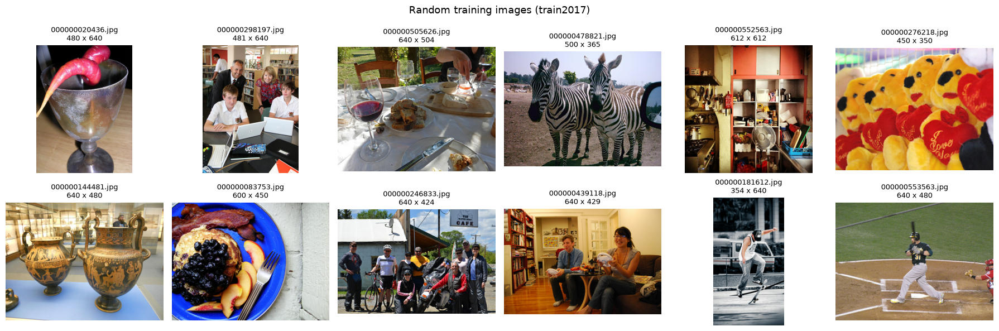

In [4]:
def decode(path):
    # file -> float32 RGB image in [0, 1]; a shorter side below MIN_SIDE is upscaled to MIN_SIDE
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img.set_shape([None, None, 3])
    hw = tf.cast(tf.shape(img)[:2], tf.float32)
    scale = tf.maximum(1.0, MIN_SIDE / tf.reduce_min(hw))
    return tf.cond(scale > 1.0, lambda: tf.image.resize(img, tf.cast(tf.math.ceil(hw * scale), tf.int32)), lambda: img)


fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, p in zip(axes.ravel(), np.random.default_rng(1).choice(paths["train"], 12, replace=False)):
    img = decode(p).numpy()
    ax.imshow(img); ax.set_title(f"{Path(p).name}\n{img.shape[1]} x {img.shape[0]}", fontsize=9); ax.axis("off")
plt.suptitle("Random training images (train2017)", fontsize=13); plt.tight_layout(); plt.show()

**Reading.** All 163,957 files decode. 267 are grayscale, and 1,124 are upscaled (the smallest shorter side is 51 px). There are 16 groups of exact duplicates, 3 of them shared between train and test. The 17 redundant training copies are removed, leaving 118,270 training images. One val/test pair is kept, since neither split is used for training.

## Section 3 - Are the supplied images clean? (beyond the brief)

Training assumes clean targets. Residual noise is estimated with Immerkaer's estimator, a Laplacian-difference kernel on luminance. It gives an upper bound, since texture also responds to the kernel. The estimator is calibrated by adding Gaussian noise of known sigma.

*Why:* the method learns to reproduce its targets. If they were noisy, the network would learn to keep that noise, and the measured PSNR would be relative to noisy references.

Estimated noise level sigma_hat ([0, 1] scale; 0.01 = 2.55 grey levels):


,count,50%,90%,99%,max,share > 0.01,share > 0.03
split,,,,,,,
train,2000.0,0.0156,0.0380,0.0746,0.2057,0.7310,0.1720
val,2000.0,0.0155,0.0396,0.0742,0.2084,0.7280,0.1810
test,2000.0,0.0158,0.0401,0.0722,0.1040,0.7295,0.1955


Calibration on 300 validation images:


,added sigma,median sigma_hat,expected sqrt(s0^2 + s^2)
0,0.00,0.0147,0.0147
1,0.02,0.0218,0.0248
2,0.05,0.0379,0.0521
3,0.10,0.0672,0.1011


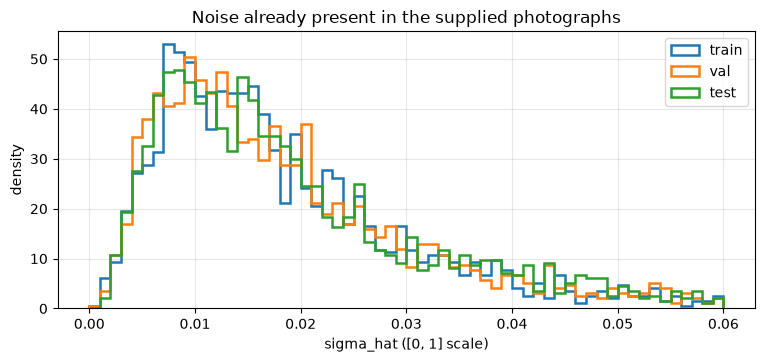

In [5]:
LAPLACE_DIFF = tf.constant([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], tf.float32)[:, :, None, None]


def immerkaer_sigma(img):
    # img: float32 (H, W, 3) in [0, 1] -> estimated noise standard deviation, [0, 1] scale
    g = tf.image.rgb_to_grayscale(img)[None]
    c = tf.nn.conv2d(g, LAPLACE_DIFF, 1, "VALID")
    n = tf.cast(tf.size(c), tf.float32)
    return math.sqrt(math.pi / 2) * tf.reduce_sum(tf.abs(c)) / (6.0 * n)


def sigma_estimates(file_list, extra_sigma=0.0):
    def one(i, p):
        img = decode(p)
        if extra_sigma > 0:
            img = tf.clip_by_value(img + extra_sigma * tf.random.stateless_normal(tf.shape(img), [SEED, i]), 0.0, 1.0)
        return immerkaer_sigma(img)
    ds = tf.data.Dataset.from_tensor_slices((tf.range(len(file_list)), file_list)).map(one, num_parallel_calls=PARALLEL_CALLS)
    return np.array(list(ds.as_numpy_iterator()))


noise_file = CACHE_DIR / f"noise_estimates_{N_NOISE_PROBE}.csv"
if noise_file.exists():
    probe = pd.read_csv(noise_file)
else:
    rng = np.random.default_rng(SEED)
    probe = pd.concat([pd.DataFrame({"split": s, "path": sample, "sigma": sigma_estimates(sample)})
                       for s in SPLITS for sample in [list(rng.choice(paths[s], min(N_NOISE_PROBE, len(paths[s])), replace=False))]])
    probe.to_csv(noise_file, index=False)

stats = probe.groupby("split", sort=False)["sigma"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]
stats["share > 0.01"] = probe.groupby("split", sort=False)["sigma"].apply(lambda s: (s > 0.01).mean())
stats["share > 0.03"] = probe.groupby("split", sort=False)["sigma"].apply(lambda s: (s > 0.03).mean())
print("Estimated noise level sigma_hat ([0, 1] scale; 0.01 = 2.55 grey levels):")
display(stats.round(4))

calib_files = list(probe[probe.split == "val"].path[:300])
s0 = sigma_estimates(calib_files)
calib = pd.DataFrame([{"added sigma": s, "median sigma_hat": np.median(sigma_estimates(calib_files, s) if s else s0),
                       "expected sqrt(s0^2 + s^2)": np.median(np.sqrt(s0 ** 2 + s ** 2))} for s in (0.0, 0.02, 0.05, 0.1)])
print("Calibration on 300 validation images:")
display(calib.round(4))

plt.figure(figsize=(9, 3.6))
for s in SPLITS:
    plt.hist(probe[probe.split == s].sigma, bins=60, range=(0, 0.06), histtype="step", lw=1.8, density=True, label=s)
plt.xlabel("sigma_hat ([0, 1] scale)"); plt.ylabel("density"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Noise already present in the supplied photographs"); plt.show()

**Reading.** The estimator reads injected per-channel noise at 0.668 sigma. This is exactly the RGB-to-luminance attenuation sqrt(0.299² + 0.587² + 0.114²), so the estimator is consistent once that factor is accounted for. The supplied images read 0.0156 (median, the same in all three splits). Even if this were all noise, it would be at most about 6 grey levels per channel, 2.5 times below the weakest test condition. The targets are therefore clean relative to the added noise, though not noise-free: the model learns to restore COCO quality, including its residual noise and JPEG artefacts.

## Section 4 - Splits and evaluation sets

Training uses random 128 x 128 crops of `train2017`, with random horizontal flips. Vertical flips and rotations are not used, since natural images are not invariant to them. Validation and test use fixed 256 x 256 centre crops, stored as `uint8`. The validation crops form three disjoint subsets, for early stopping, scoring and filter tuning. The 1,000 test images are used once, on the final model.

In [6]:
rng = np.random.default_rng(SEED)
val_order = rng.permutation(paths["val"])
val_sets = {"monitor": val_order[:N_VAL_MONITOR],
            "score":   val_order[N_VAL_MONITOR:N_VAL_MONITOR + N_VAL_SCORE],
            "tune":    val_order[N_VAL_MONITOR + N_VAL_SCORE:N_VAL_MONITOR + N_VAL_SCORE + N_VAL_TUNE]}
test_paths = sorted(str(p) for p in rng.choice(paths["test"], N_TEST, replace=False))


def center_crop(path):
    return tf.image.resize_with_crop_or_pad(decode(path), EVAL_SIZE, EVAL_SIZE)


def load_crops(file_list):
    ds = tf.data.Dataset.from_tensor_slices(list(file_list)).map(center_crop, num_parallel_calls=PARALLEL_CALLS)
    return np.stack([np.round(c * 255).astype(np.uint8) for c in ds.as_numpy_iterator()])


val_u8 = {k: load_crops(v) for k, v in val_sets.items()}
test_u8 = load_crops(test_paths)
display(pd.DataFrame({"images": [len(paths["train"])] + [len(v) for v in val_u8.values()] + [len(test_u8)],
                      "used as": ["random 128 x 128 crops, fresh noise"] + [f"256 x 256 centre crops ({k})" for k in val_u8] + ["256 x 256 centre crops"]},
                     index=["train2017", "val2017 / monitor", "val2017 / score", "val2017 / tune", "test2017 subset"]))

,images,used as
train2017,118270,"random 128 x 128 crops, fresh noise"
val2017 / monitor,300,256 x 256 centre crops (monitor)
val2017 / score,500,256 x 256 centre crops (score)
val2017 / tune,200,256 x 256 centre crops (tune)
test2017 subset,1000,256 x 256 centre crops


## Section 5 - Noise models

With x in [0, 1] per channel, and the result clipped to [0, 1]:
* Gaussian: y = x + sigma n (sensor noise);
* salt and pepper: a fraction p of the pixels is set to 0 or 1 (dead pixels, dust);
* speckle: y = x + sigma x n (multiplicative noise);
* Poisson: y = Poisson(peak x) / peak (shot noise; the lower the peak, the stronger the noise).

Training is blind. Each crop is clean with probability 0.1; otherwise it receives one noise type with a random strength (Gaussian sigma up to 51/255, p up to 0.1, speckle sigma up to 0.4, peak 5 to 100). The test uses 8 fixed conditions plus clean inputs; Gaussian sigma = 75/255 lies outside the training range. Evaluation noise is drawn with stateless seeds, so all methods are compared on identical inputs.

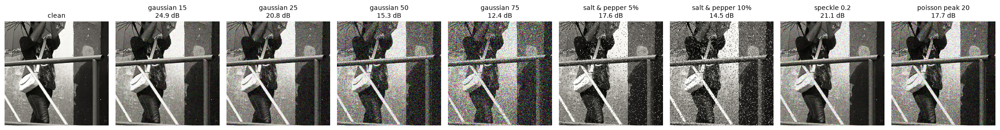

In [7]:
def _seed(seed):
    # None -> a new random key at every call (training); otherwise the given key (evaluation)
    return tf.random.uniform([2], 0, 2**31 - 1, dtype=tf.int32) if seed is None else tf.cast(seed, tf.int32)


def add_noise(clean, kind, level, seed=None):
    # clean: float32 (N, H, W, 3) in [0, 1]. level: a number or one value per image, shape (N, 1, 1, 1).
    # seed: None, or a pair of ints; streams are separated by offsetting its second element.
    shape = tf.shape(clean)
    key = None if seed is None else tf.stack([seed[0], seed[1] * 8])
    def k(stream):
        return None if key is None else key + tf.constant([0, stream])
    if kind == "none":
        noisy = clean
    elif kind == "gaussian":
        noisy = clean + level * tf.random.stateless_normal(shape, _seed(k(1)))
    elif kind == "salt_pepper":
        u = tf.random.stateless_uniform(tf.concat([shape[:3], [1]], 0), _seed(k(2)))   # one draw per pixel
        noisy = tf.where(u < level / 2, 0.0, tf.where(u > 1 - level / 2, 1.0, clean))
    elif kind == "speckle":
        noisy = clean + clean * level * tf.random.stateless_normal(shape, _seed(k(3)))
    elif kind == "poisson":
        noisy = tf.random.stateless_poisson(shape, _seed(k(4)), lam=clean * level, dtype=tf.float32) / level
    else:
        raise ValueError(kind)
    return tf.clip_by_value(noisy, 0.0, 1.0)


def random_noisy_batch(clean, seed=None):
    # Blind training mixture: a random noise type and strength for every image of the batch.
    n = tf.shape(clean)[0]
    def per_image(stream, lo, hi):
        s = None if seed is None else tf.stack([seed[0], seed[1] * 8 + 100 + stream])
        return tf.random.stateless_uniform([n, 1, 1, 1], _seed(s), lo, hi)
    sub = lambda j: None if seed is None else tf.stack([seed[0] + 1000 * j, seed[1]])
    gauss   = add_noise(clean, "gaussian", per_image(0, 0.0, 0.2), sub(1))
    sp      = add_noise(clean, "salt_pepper", per_image(1, 0.0, 0.1), sub(2))
    speck   = add_noise(clean, "speckle", per_image(2, 0.0, 0.4), sub(3))
    poisson = add_noise(clean, "poisson", tf.exp(per_image(3, math.log(5.0), math.log(100.0))), sub(4))
    pick = per_image(4, 0.0, 1.0)
    return tf.where(pick < 0.100, clean, tf.where(pick < 0.325, gauss, tf.where(pick < 0.550, sp,
           tf.where(pick < 0.775, speck, poisson))))


CONDITIONS = {                                  # name: (noise type, parameter)
    "clean":            ("none", 0.0),
    "gaussian 15":      ("gaussian", 15 / 255),
    "gaussian 25":      ("gaussian", 25 / 255),
    "gaussian 50":      ("gaussian", 50 / 255),
    "gaussian 75":      ("gaussian", 75 / 255),   # outside the training range (<= 51/255)
    "salt & pepper 5%": ("salt_pepper", 0.05),
    "salt & pepper 10%": ("salt_pepper", 0.10),
    "speckle 0.2":      ("speckle", 0.2),
    "poisson peak 20":  ("poisson", 20.0),
}
NOISY_CONDITIONS = [c for c in CONDITIONS if c != "clean"]
EVAL_BLOCK = 100                                # images per noise key: the noise of an image depends only on (condition, block)


def noisy_blocks(clean_u8, condition, base_seed=SEED):
    # Yields (start index, noisy float32, clean float32) blocks; identical at every call for given inputs.
    kind, level = CONDITIONS[condition]
    cid = list(CONDITIONS).index(condition)
    for start in range(0, len(clean_u8), EVAL_BLOCK):
        clean = tf.convert_to_tensor(clean_u8[start:start + EVAL_BLOCK], tf.float32) / 255.0
        noisy = add_noise(clean, kind, level, seed=tf.constant([base_seed + cid, start]))
        yield start, noisy.numpy(), clean.numpy()


def make_noisy(clean_u8, condition, base_seed=SEED):
    return np.concatenate([n for _, n, _ in noisy_blocks(clean_u8, condition, base_seed)])


def psnr_of(clean, other):
    # per-image PSNR in dB, capped at 60 dB (RMSE < 0.26 grey level counts as identical)
    return np.minimum(tf.image.psnr(tf.convert_to_tensor(clean), tf.convert_to_tensor(other), 1.0).numpy(), 60.0)


demo = test_u8[3:4]
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(22, 3.3))
for ax, cond in zip(axes, CONDITIONS):
    noisy = make_noisy(demo, cond)
    ax.imshow(noisy[0]); ax.axis("off")
    ax.set_title(cond if cond == "clean" else f"{cond}\n{psnr_of(demo / 255.0, noisy)[0]:.1f} dB", fontsize=10)
plt.tight_layout(); plt.show()

## Section 6 - Training and validation pipelines

A `tf.data` pipeline draws fresh crops and fresh noise at every step, so training pairs never repeat. A fixed noisy validation set drives early stopping. Metrics are computed per image: PSNR, capped at 60 dB so that an unchanged image keeps a finite score, and SSIM.

Validation monitor: (300, 256, 256, 3), mean PSNR of the noisy inputs 23.89 dB


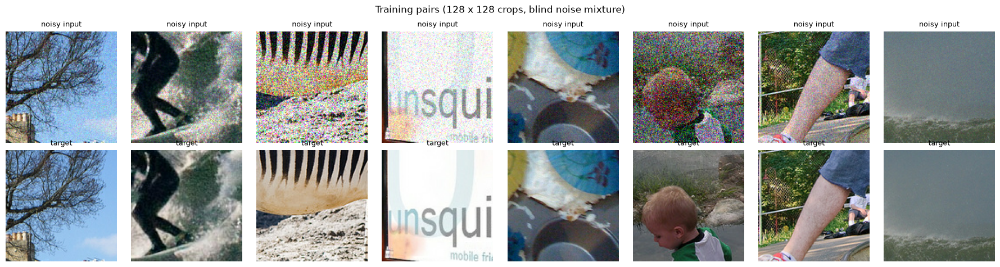

In [8]:
def train_example(path):
    img = tf.image.random_crop(decode(path), (PATCH, PATCH, 3))
    return tf.image.random_flip_left_right(img)


train_ds = (tf.data.Dataset.from_tensor_slices(paths["train"])
            .shuffle(len(paths["train"]), seed=SEED, reshuffle_each_iteration=True)
            .map(train_example, num_parallel_calls=PARALLEL_CALLS)
            .batch(BATCH_SIZE, drop_remainder=True)
            .map(lambda clean: (random_noisy_batch(clean), clean), num_parallel_calls=PARALLEL_CALLS)
            .repeat()
            .prefetch(2))

val_clean = val_u8["monitor"].astype("float32") / 255.0
val_noisy = np.concatenate([random_noisy_batch(tf.constant(val_clean[i:i + EVAL_BLOCK]), seed=tf.constant([SEED, i])).numpy()
                            for i in range(0, len(val_clean), EVAL_BLOCK)])
print(f"Validation monitor: {val_noisy.shape}, mean PSNR of the noisy inputs {psnr_of(val_clean, val_noisy).mean():.2f} dB")

xb, yb = next(iter(train_ds))
fig, axes = plt.subplots(2, 8, figsize=(18, 4.8))
for i in range(8):
    axes[0, i].imshow(xb[i]); axes[0, i].set_title("noisy input", fontsize=9); axes[0, i].axis("off")
    axes[1, i].imshow(yb[i]); axes[1, i].set_title("target", fontsize=9); axes[1, i].axis("off")
plt.suptitle("Training pairs (128 x 128 crops, blind noise mixture)", fontsize=12); plt.tight_layout(); plt.show()

## Section 7 - Baselines: convolution filters

Gaussian filters (sigma from 0.5 to 2) and median filters (3 x 3 and 5 x 5) are used, with the best parameter chosen on validation for each test condition. The filters therefore know the noise type and level, while the autoencoder is blind, which makes this an optimistic baseline.

*Beyond the brief:* the tuning. With fixed parameters, the filters would be weak at some noise levels and exaggerate the autoencoder's advantage.

In [9]:
def gaussian_filter(x, sigma):
    r = max(1, math.ceil(3 * sigma))
    ax = np.arange(-r, r + 1)
    k = np.exp(-(ax[:, None] ** 2 + ax[None, :] ** 2) / (2 * sigma ** 2))
    kernel = tf.constant(np.tile((k / k.sum())[:, :, None, None], (1, 1, 3, 1)), tf.float32)
    x = tf.pad(x, [[0, 0], [r, r], [r, r], [0, 0]], "REFLECT")
    return tf.nn.depthwise_conv2d(x, kernel, [1, 1, 1, 1], "VALID")


def median_filter(x, size):
    with tf.device("/CPU:0"):                       # sorting is about 15 times faster on the CPU than on the GPU here
        r = size // 2
        s = tf.shape(x)
        x = tf.pad(x, [[0, 0], [r, r], [r, r], [0, 0]], "REFLECT")
        windows = tf.image.extract_patches(x, [1, size, size, 1], [1, 1, 1, 1], [1, 1, 1, 1], "VALID")
        windows = tf.reshape(windows, [s[0], s[1], s[2], size * size, 3])
        return tf.sort(windows, axis=3)[:, :, :, size * size // 2, :]


def in_chunks(fn, x, chunk=8):
    return np.concatenate([np.asarray(fn(tf.constant(x[i:i + chunk]))) for i in range(0, len(x), chunk)])


FILTER_GRID = {"Gaussian filter": (gaussian_filter, [0.5, 0.75, 1.0, 1.5, 2.0]),
               "Median filter": (median_filter, [3, 5])}
tuned, tuning_rows = {name: {} for name in FILTER_GRID}, []
for cond in CONDITIONS:
    noisy = make_noisy(val_u8["tune"], cond, base_seed=SEED + 200)
    clean = val_u8["tune"] / 255.0
    for name, (fn, grid) in FILTER_GRID.items():
        scores = {p: psnr_of(clean, np.clip(in_chunks(lambda b: fn(b, p), noisy), 0, 1)).mean() for p in grid}
        tuned[name][cond] = max(scores, key=scores.get)
        tuning_rows.append({"condition": cond, "filter": name, "best setting": tuned[name][cond]})
print(f"Best setting of each filter per condition ({N_VAL_TUNE} validation crops):")
display(pd.DataFrame(tuning_rows).pivot(index="filter", columns="condition", values="best setting")[list(CONDITIONS)])

Best setting of each filter per condition (200 validation crops):


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
filter,,,,,,,,,
Gaussian filter,0.5,0.5,0.75,1.5,1.5,1.0,1.5,0.75,1.0
Median filter,3.0,3.0,3.00,5.0,5.0,3.0,3.0,3.00,5.0


## Section 8 - The convolutional autoencoders

All models are encoder-decoder convolutional autoencoders in the line of the workshop model: convolutions and down-sampling compress the image, up-sampling and convolutions reconstruct it. Each design step changes one component of the previous one.

1. **Workshop autoencoder**, adapted to RGB: two levels of one 32-filter convolution (4x down-sampling), a sigmoid output and a BCE loss.
2. **U-Net**: the same encoder-decoder made deeper (4 levels of two 3 x 3 convolutions with batch normalisation and ReLU, 32 to 256 filters, 512 at the bottleneck), with skip connections that let edges and texture bypass the bottleneck. Sigmoid output, BCE loss. Up-sampling is nearest-neighbour followed by convolutions, which avoids checkerboard artefacts.
3. **Residual output and MAE loss**: the network predicts a correction r(y) and outputs clip(y + r(y), 0, 1), so the identity needed for clean inputs corresponds to r = 0. With MSE, the residual model degraded clean images, because the loss is dominated by impulse-noise pixels; MAE does not.
4. **Residual-block U-Net (final model)**, after DRUNet (Zhang et al., 2021). Each level is a stack of 4 residual blocks x + 0.2 g(x), with g = conv 3x3, ReLU, conv 3x3, at 64, 128 and 256 filters, and 512 at the bottleneck. Down-sampling is a learned 2 x 2 stride-2 convolution, up-sampling a 2 x 2 transposed convolution, and skips are added rather than concatenated. The residual output and MAE loss of step 3 are kept.
   * There is no batch normalisation. Its statistics depend on the batch and the crop size, while the denoiser is applied to whole photographs one at a time.
   * Without normalisation, the residual sums grow with depth. The 0.2 factor bounds them at initialisation; without it, training diverged in the first epoch.

All models are trained with Adam and a cosine learning-rate schedule decayed to 1 % of its peak (1e-3; 2e-4 for step 4). The weights kept are those with the lowest validation loss.

**Choice of the final architecture.** Preliminary runs of 15,000 steps, scored like Section 9 on the 500 validation crops (mean PSNR over the 8 noisy conditions):

| model | weights | noisy (dB) | clean (dB) |
|---|---|---|---|
| BN U-Net, 32 filters (step 3) | 7.9 M | 28.89 | 52.4 |
| BN U-Net, 48 filters | 17.7 M | 29.38 | 51.8 |
| BN U-Net, 64 filters | 31.4 M | 29.48 | 49.1 |
| residual-block U-Net, 2 blocks per level | 17.0 M | 29.66 | 54.7 |
| residual-block U-Net, 4 blocks per level | 32.7 M | 30.22 | 55.5 |

Widening the BN U-Net saturates (+0.10 dB from 48 to 64 filters) and lowers the clean-input score. At equal weight count, the residual-block U-Net is 0.74 dB better and keeps clean images intact, and depth within each level still pays (+0.56 dB from 2 to 4 blocks).

In [10]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def residual_output(inputs, x, kernel=1):
    # clip(y + r(y), 0, 1): the identity corresponds to r = 0 (output layers kept in float32)
    correction = layers.Conv2D(3, kernel, padding="same", name="noise_correction", dtype="float32")(x)
    return layers.ReLU(max_value=1.0, name="clean_image", dtype="float32")(layers.Add(dtype="float32")([inputs, correction]))


def build_workshop_ae():
    inputs = keras.Input(shape=(None, None, 3), name="noisy_image")
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(2, padding="same")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(3, 3, activation="sigmoid", padding="same", name="clean_image", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="workshop_ae")


def build_unet(residual=True, base=BASE_FILTERS, depth=DEPTH):
    inputs = keras.Input(shape=(None, None, 3), name="noisy_image")
    x, skips = inputs, []
    for d in range(depth):
        x = conv_block(x, base * 2 ** d)
        skips.append(x)
        x = layers.MaxPooling2D()(x)
    x = conv_block(x, base * 2 ** depth)                      # bottleneck
    for d in reversed(range(depth)):
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, skips[d]])               # skip connection
        x = conv_block(x, base * 2 ** d)
    if residual:
        outputs = residual_output(inputs, x)
    else:
        outputs = layers.Conv2D(3, 1, activation="sigmoid", name="clean_image", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="unet" + ("_residual" if residual else ""))


def res_block(x, filters, scale=0.2):
    # x + scale * g(x): the scale bounds the sum of residual branches at initialisation (no normalisation layer)
    y = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    y = layers.Conv2D(filters, 3, padding="same")(y)
    return layers.Add()([x, layers.Rescaling(scale)(y)])


def build_resunet(base=RES_FILTERS, depth=RES_DEPTH, blocks=RES_BLOCKS):
    inputs = keras.Input(shape=(None, None, 3), name="noisy_image")
    x = layers.Conv2D(base, 3, padding="same", name="head")(inputs)
    skips = []
    for d in range(depth):
        for _ in range(blocks):
            x = res_block(x, base * 2 ** d)
        skips.append(x)
        x = layers.Conv2D(base * 2 ** (d + 1), 2, strides=2, name=f"down{d}")(x)    # learned down-sampling
    for _ in range(blocks):
        x = res_block(x, base * 2 ** depth)                                         # bottleneck
    for d in reversed(range(depth)):
        x = layers.Conv2DTranspose(base * 2 ** d, 2, strides=2, name=f"up{d}")(x)    # learned up-sampling
        x = layers.Add()([x, skips[d]])                                              # additive skip connection
        for _ in range(blocks):
            x = res_block(x, base * 2 ** d)
    return keras.Model(inputs, residual_output(inputs, x, kernel=3), name="resunet")


def psnr(y_true, y_pred):
    return tf.image.psnr(y_true, tf.cast(y_pred, tf.float32), max_val=1.0)


for m in [build_workshop_ae(), build_unet(residual=False), build_unet(), build_resunet()]:
    print(f"{m.name:<15} {m.count_params():>11,} weights")

workshop_ae          29,507 weights
unet              7,855,555 weights
unet_residual     7,855,555 weights
resunet          32,653,059 weights


## Section 9 - Training and main design steps

The four models of Section 8 are trained for `STEP_EPOCHS` epochs on the same pipeline, one design step each, so that every gain is measured at equal budget. The final model (step 4) is then trained for `FINAL_EPOCHS` epochs. Computation is in float16 with float32 weights and outputs. All models are scored on validation, and the final model must reach at least 35 dB on clean inputs. The final model and its training curves are saved in `cache/`, and reloaded when present instead of being retrained. This first-stage model is the starting point of the fine-tuning in Section 13, which produces the delivered model.

In [11]:
def train(build, loss, epochs, lr=LEARNING_RATE, checkpoint=str(CACHE_DIR / "checkpoint.weights.h5")):
    # trains a fresh model with a cosine schedule; returns a float32 copy holding the best validation weights, and the history
    keras.utils.set_random_seed(SEED)
    keras.mixed_precision.set_global_policy("mixed_float16")
    model = build()
    keras.mixed_precision.set_global_policy("float32")
    schedule = keras.optimizers.schedules.CosineDecay(lr, decay_steps=epochs * STEPS_PER_EPOCH, alpha=0.01)
    model.compile(optimizer=keras.optimizers.Adam(schedule), loss=loss, metrics=[psnr], jit_compile=True)
    best = keras.callbacks.ModelCheckpoint(checkpoint, monitor="val_loss", save_best_only=True, save_weights_only=True)
    history = model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=epochs, validation_data=(val_noisy, val_clean),
                        validation_batch_size=16, callbacks=[best], verbose=2).history
    model.load_weights(checkpoint)
    copy = build()
    copy.set_weights(model.get_weights())
    return copy, history


workshop_ae, h_workshop = train(build_workshop_ae, "binary_crossentropy", STEP_EPOCHS)
unet_sigmoid, h_unet = train(lambda: build_unet(residual=False), "binary_crossentropy", STEP_EPOCHS)
unet_residual, h_residual = train(build_unet, "mae", STEP_EPOCHS)
resunet_step, h_resunet = train(build_resunet, "mae", STEP_EPOCHS, lr=RES_LEARNING_RATE)

if MODEL_PATH.exists() and HISTORY_PATH.exists():
    denoiser = keras.models.load_model(MODEL_PATH, compile=False)
    h_final = json.load(open(HISTORY_PATH))
    print(f"Final model reloaded from {MODEL_PATH} ({denoiser.count_params():,} weights)")
else:
    denoiser, h_final = train(build_resunet, "mae", FINAL_EPOCHS, lr=RES_LEARNING_RATE)
    denoiser.save(MODEL_PATH)
    json.dump(h_final, open(HISTORY_PATH, "w"))

Epoch 1/6


1000/1000 - 36s - 36ms/step - loss: 0.5267 - psnr: 22.1092 - val_loss: 0.5225 - val_psnr: 22.8375


Epoch 2/6


1000/1000 - 23s - 23ms/step - loss: 0.5184 - psnr: 23.8823 - val_loss: 0.5206 - val_psnr: 23.2275


Epoch 3/6


1000/1000 - 23s - 23ms/step - loss: 0.5161 - psnr: 24.3691 - val_loss: 0.5207 - val_psnr: 23.1399


... (39 outputs left out)

1000/1000 - 189s - 189ms/step - loss: 0.0183 - psnr: 33.3724 - val_loss: 0.0184 - val_psnr: 32.7670


Epoch 6/6


1000/1000 - 188s - 188ms/step - loss: 0.0176 - psnr: 33.8253 - val_loss: 0.0182 - val_psnr: 32.8695


Final model reloaded from denoiser_coco.keras (32,653,059 weights)


Main design steps, validation (500 crops x 9 conditions):


,weights,mean noisy PSNR (dB),clean PSNR (dB),mean noisy SSIM,gain vs previous (dB)
1. Workshop AE (6 ep.),29507,23.400000,24.590000,0.625,NaN
"2. U-Net, sigmoid, BCE (6 ep.)",7855555,26.280001,31.650000,0.756,2.88
"3. U-Net, residual, MAE (6 ep.)",7855555,27.809999,49.349998,0.779,1.53
4. Residual-block U-Net (6 ep.),32653059,28.900000,49.810001,0.833,1.09
"4. Residual-block U-Net (final, 60 ep.)",32653059,31.650000,59.529999,0.877,2.75


Validation PSNR (dB) per condition:


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
method,,,,,,,,,
1. Workshop AE (6 ep.),24.590000,24.420000,24.090000,22.879999,21.370001,23.770000,22.910000,24.120001,23.600000
"2. U-Net, sigmoid, BCE (6 ep.)",31.650000,29.080000,27.340000,24.070000,21.440001,28.330000,25.969999,27.940001,26.110001
"3. U-Net, residual, MAE (6 ep.)",49.349998,30.780001,28.250000,24.480000,21.650000,33.000000,28.959999,28.840000,26.530001
4. Residual-block U-Net (6 ep.),49.810001,31.820000,29.340000,25.920000,22.650000,33.459999,30.280001,29.990000,27.750000
"4. Residual-block U-Net (final, 60 ep.)",59.529999,33.040001,30.639999,27.500000,23.809999,40.529999,36.980000,31.580000,29.139999


Clean-input requirement (>= 35 dB): 59.53 dB -> met
Final model: best epoch 58 of 60, monitor PSNR 37.41 dB


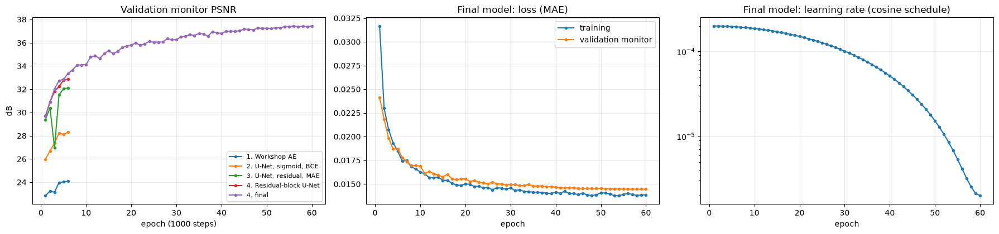

In [12]:
def predict(model):
    fn = tf.function(lambda x: model(x, training=False))
    return lambda x, cond=None: np.concatenate([fn(tf.constant(x[i:i + 16])).numpy() for i in range(0, len(x), 16)])


def summary(scores, metric="PSNR", digits=2):
    table = scores.pivot_table(index="method", columns="condition", values=metric, aggfunc="mean", sort=False)
    return table[[c for c in CONDITIONS if c in table.columns]].round(digits)


def run_all(methods, clean_u8, base_seed=SEED, encoder=False):
    # Per-image metrics of every method under every condition, on bit-identical noisy inputs.
    rows = []
    for cond in CONDITIONS:
        for start, noisy, clean in noisy_blocks(clean_u8, cond, base_seed):
            ref = encoder_outputs(clean) if encoder else None
            for name, method in methods.items():
                out = np.clip(method(noisy, cond), 0.0, 1.0).astype("float32")
                df = pd.DataFrame({"method": name, "condition": cond, "image": np.arange(start, start + len(clean)),
                                   "PSNR": psnr_of(clean, out),
                                   "SSIM": tf.image.ssim(tf.constant(clean), tf.constant(out), 1.0).numpy()})
                if encoder:
                    feat, top1 = encoder_outputs(out)
                    df["feature cosine"] = np.sum(feat * ref[0], axis=1)
                    df["same top-1"] = top1 == ref[1]
                rows.append(df)
    return pd.concat(rows, ignore_index=True)


steps = {f"1. Workshop AE ({STEP_EPOCHS} ep.)": workshop_ae,
         f"2. U-Net, sigmoid, BCE ({STEP_EPOCHS} ep.)": unet_sigmoid,
         f"3. U-Net, residual, MAE ({STEP_EPOCHS} ep.)": unet_residual,
         f"4. Residual-block U-Net ({STEP_EPOCHS} ep.)": resunet_step,
         f"4. Residual-block U-Net (final, {FINAL_EPOCHS} ep.)": denoiser}
val_scores = run_all({name: predict(m) for name, m in steps.items()}, val_u8["score"], base_seed=SEED + 100)

val_psnr = summary(val_scores)
table = pd.DataFrame({"weights": [m.count_params() for m in steps.values()]}, index=list(steps))
table["mean noisy PSNR (dB)"] = val_psnr[NOISY_CONDITIONS].mean(axis=1).round(2)
table["clean PSNR (dB)"] = val_psnr["clean"]
table["mean noisy SSIM"] = summary(val_scores, "SSIM", 3)[NOISY_CONDITIONS].mean(axis=1).round(3)
table["gain vs previous (dB)"] = table["mean noisy PSNR (dB)"].diff().round(2)
print(f"Main design steps, validation ({N_VAL_SCORE} crops x 9 conditions):")
display(table)
print("Validation PSNR (dB) per condition:")
display(val_psnr)
final_clean = table["clean PSNR (dB)"].iloc[-1]
print(f"Clean-input requirement (>= 35 dB): {final_clean:.2f} dB -> {'met' if final_clean >= 35 else 'NOT met'}")

h = h_final
best = int(np.argmin(h["val_loss"]))
print(f"Final model: best epoch {best + 1} of {len(h['loss'])}, monitor PSNR {h['val_psnr'][best]:.2f} dB")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for name, hist in [("1. Workshop AE", h_workshop), ("2. U-Net, sigmoid, BCE", h_unet), ("3. U-Net, residual, MAE", h_residual),
                   ("4. Residual-block U-Net", h_resunet), ("4. final", h_final)]:
    ax[0].plot(range(1, len(hist["val_psnr"]) + 1), hist["val_psnr"], "o-", ms=3, label=name)
ax[0].set_title("Validation monitor PSNR"); ax[0].set_xlabel(f"epoch ({STEPS_PER_EPOCH} steps)"); ax[0].set_ylabel("dB")
ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
epochs_run = range(1, len(h["loss"]) + 1)
ax[1].plot(epochs_run, h["loss"], "o-", ms=3, label="training"); ax[1].plot(epochs_run, h["val_loss"], "o-", ms=3, label="validation monitor")
ax[1].set_title("Final model: loss (MAE)"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=0.3); ax[1].legend()
schedule = keras.optimizers.schedules.CosineDecay(RES_LEARNING_RATE, decay_steps=FINAL_EPOCHS * STEPS_PER_EPOCH, alpha=0.01)
ax[2].plot(epochs_run, [float(schedule(e * STEPS_PER_EPOCH)) for e in epochs_run], "o-", ms=3); ax[2].set_yscale("log")
ax[2].set_title("Final model: learning rate (cosine schedule)"); ax[2].set_xlabel("epoch"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading.** On validation, averaged over the noisy conditions, at equal budget:
* **Skip connections** bring +2.9 dB over the workshop AE (23.4 to 26.3 dB).
* **The residual output with MAE** adds +1.5 dB (27.8 dB). Its main effect is on clean inputs, which go from 31.7 to 49.3 dB; the workshop AE blurs even clean images (24.6 dB).
* **Residual blocks with learned resampling** add +1.1 dB (28.9 dB) and are better under every condition, with 4 times the weights. The pilot table of Section 8 shows that width alone does not buy this gain.

**Training to convergence** adds +2.75 dB, reaching 31.65 dB on noisy inputs and 59.5 dB on clean ones. The largest gains are on impulse noise (+7.1 dB at 5 % salt and pepper). The best epoch is 58 of 60, at the end of the cosine schedule.

Test scores match validation (31.95 versus 31.65 dB), so there is no sign of overfitting. Fresh noise at every step also makes memorisation impossible.

## Section 10 - Evaluation on the test set

Five methods are compared on the 1,000 test crops under the 9 conditions: the noisy input, the tuned Gaussian and median filters, the workshop AE and the final AE. The same pass also computes the encoder metrics of Extension E3: the last two tables below and the right-hand panel of the figure.

In [13]:
inception = keras.applications.InceptionV3(weights="imagenet", include_top=True)
encoder = keras.Model(inception.input, [inception.get_layer("avg_pool").output, inception.output])


@tf.function
def _encode(x):
    x = tf.image.resize(x, (299, 299)) * 2.0 - 1.0            # InceptionV3 preprocessing: [0, 1] -> [-1, 1]
    feat, probs = encoder(x, training=False)
    return tf.math.l2_normalize(feat, axis=1), tf.argmax(probs, axis=1)


def encoder_outputs(images):
    out = [_encode(tf.constant(images[i:i + 50])) for i in range(0, len(images), 50)]
    return np.concatenate([o[0].numpy() for o in out]), np.concatenate([o[1].numpy() for o in out])


FINAL = "Final AE"
METHODS = {
    "Noisy input":     lambda x, cond: x,
    "Gaussian filter": lambda x, cond: in_chunks(lambda b: gaussian_filter(b, tuned["Gaussian filter"][cond]), x),
    "Median filter":   lambda x, cond: in_chunks(lambda b: median_filter(b, tuned["Median filter"][cond]), x),
    "Workshop AE":     predict(workshop_ae),
    FINAL:             predict(denoiser),
}
test_scores = run_all(METHODS, test_u8, encoder=True)

print(f"Mean PSNR (dB), {N_TEST} test crops (60 = identical):")
display(summary(test_scores, "PSNR"))
print("Mean SSIM:")
display(summary(test_scores, "SSIM", 3))
print("Encoder feature cosine with the clean image (1 = same representation):")
display(summary(test_scores, "feature cosine", 3))
print("Same ImageNet top-1 class as on the clean image (%):")
display((100 * summary(test_scores, "same top-1", 4)).round(2))

Mean PSNR (dB), 1000 test crops (60 = identical):


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
method,,,,,,,,,
Noisy input,60.000000,24.900000,20.639999,15.14,12.230000,17.840000,14.83,20.760000,17.440001
Gaussian filter,35.130001,27.420000,25.230000,22.25,20.420000,23.860001,22.16,25.129999,23.590000
Median filter,27.799999,25.750000,24.040001,21.74,20.040001,27.360001,26.74,23.969999,22.350000
Workshop AE,24.969999,24.790001,24.430000,23.15,21.580000,24.090000,23.18,24.440001,23.889999
Final AE,59.619999,33.290001,30.920000,27.83,24.059999,40.950001,37.41,31.760000,29.400000


Mean SSIM:


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
method,,,,,,,,,
Noisy input,1.000,0.584,0.414,0.223,0.143,0.444,0.274,0.535,0.345
Gaussian filter,0.973,0.700,0.640,0.541,0.452,0.614,0.542,0.684,0.601
Median filter,0.819,0.681,0.561,0.436,0.334,0.813,0.803,0.605,0.488
Workshop AE,0.720,0.698,0.671,0.592,0.515,0.653,0.595,0.683,0.648
Final AE,1.000,0.917,0.876,0.798,0.706,0.993,0.983,0.905,0.849


Encoder feature cosine with the clean image (1 = same representation):


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
method,,,,,,,,,
Noisy input,1.000,0.921,0.872,0.770,0.686,0.736,0.681,0.858,0.816
Gaussian filter,0.991,0.920,0.860,0.745,0.690,0.741,0.676,0.855,0.802
Median filter,0.945,0.890,0.844,0.725,0.660,0.937,0.919,0.835,0.758
Workshop AE,0.843,0.827,0.798,0.725,0.658,0.762,0.703,0.805,0.766
Final AE,1.000,0.953,0.923,0.868,0.825,0.998,0.994,0.942,0.905


Same ImageNet top-1 class as on the clean image (%):


condition,clean,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
method,,,,,,,,,
Noisy input,100.0,65.8,53.7,36.7,20.1,27.4,19.7,52.1,43.7
Gaussian filter,87.4,65.4,50.9,28.8,20.8,28.5,17.1,51.6,39.3
Median filter,71.9,57.0,47.2,25.1,18.5,68.8,64.8,47.1,29.0
Workshop AE,47.7,45.5,39.3,25.9,15.4,32.7,22.8,38.7,32.4
Final AE,99.5,73.6,64.6,52.8,44.8,94.6,91.1,71.4,60.2


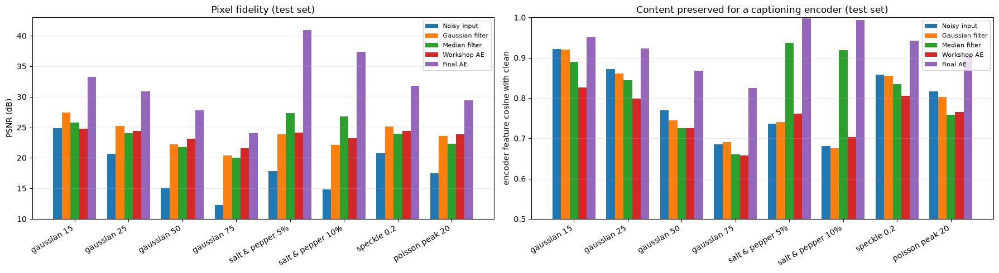

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
x = np.arange(len(NOISY_CONDITIONS))
for k, (metric, label) in enumerate([("PSNR", "PSNR (dB)"), ("feature cosine", "encoder feature cosine with clean")]):
    table = summary(test_scores, metric, 4)[NOISY_CONDITIONS]
    w = 0.8 / len(table)
    for i, m in enumerate(table.index):
        ax[k].bar(x + i * w, table.loc[m], w, label=m)
    ax[k].set_xticks(x + w * (len(table) - 1) / 2, NOISY_CONDITIONS, rotation=30, ha="right")
    ax[k].set_ylabel(label); ax[k].grid(axis="y", alpha=0.3); ax[k].legend(fontsize=8)
ax[0].set_ylim(10, None); ax[0].set_title("Pixel fidelity (test set)")
ax[1].set_ylim(0.5, 1.0); ax[1].set_title("Content preserved for a captioning encoder (test set)")
plt.tight_layout(); plt.show()

**Reading.** The final AE is the best method under every condition. Its mean PSNR over the noisy conditions is 31.95 dB, against 24.77 dB for the best tuned filter of each condition, 23.69 dB for the workshop AE and 17.97 dB for the noisy input. SSIM follows the same ranking: 0.876 at sigma = 25, against 0.640 for the best filter and 0.671 for the workshop AE.

## Extension E1 - Statistical significance

*Why:* differences of a few tenths of a dB between means over 1,000 images could be sampling noise, and a mean can hide methods that win on average but lose on many images. Since every method sees bit-identical noisy inputs, paired differences answer both questions directly.

### Paired differences
For each (image, noisy condition) pair, we compute the PSNR difference between the final AE and each other method. We report the mean with a 95 % confidence interval, the worst case, and the share of pairs won. For top-1 rates on 1,000 images, the 95 % half-width is at most 3.1 points.

,mean gain (dB),95% CI (dB),worst case (dB),final AE better in,pairs
final AE vs,,,,,
Noisy input,13.98,+- 0.137,1.67,100.00%,8000
Gaussian filter,8.19,+- 0.112,0.58,100.00%,8000
Median filter,7.95,+- 0.070,-2.89,99.75%,8000
Workshop AE,8.26,+- 0.108,-2.07,99.56%,8000


Share of test images where the final AE has the higher PSNR (%):


condition,gaussian 15,gaussian 25,gaussian 50,gaussian 75,salt & pepper 5%,salt & pepper 10%,speckle 0.2,poisson peak 20
vs Workshop AE,100.0,100.0,100.0,96.5,100.0,100.0,100.0,100.0
vs best filter (per image),100.0,100.0,100.0,98.0,100.0,100.0,100.0,100.0


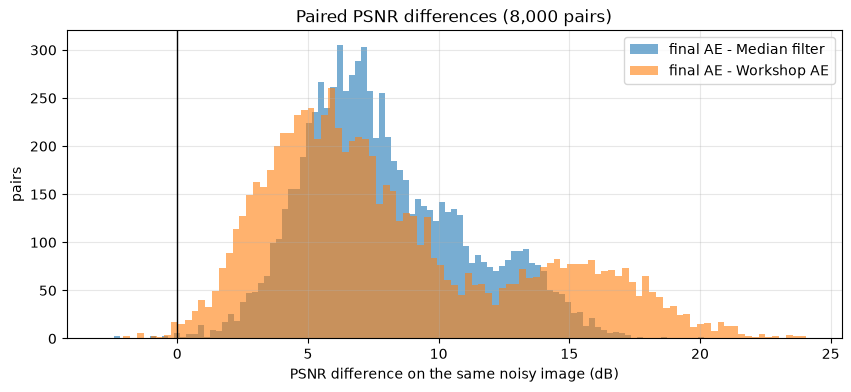

In [15]:
wide = test_scores[test_scores.condition != "clean"].pivot_table(index=["condition", "image"], columns="method", values="PSNR")
rows = []
for other in ["Noisy input", "Gaussian filter", "Median filter", "Workshop AE"]:
    d = wide[FINAL] - wide[other]
    rows.append({"final AE vs": other, "mean gain (dB)": round(d.mean(), 2), "95% CI (dB)": f"+- {1.96 * d.std() / np.sqrt(len(d)):.3f}",
                 "worst case (dB)": round(d.min(), 2), "final AE better in": f"{(d > 0).mean():.2%}", "pairs": len(d)})
display(pd.DataFrame(rows).set_index("final AE vs"))

best_filter = np.maximum(wide["Gaussian filter"], wide["Median filter"])
per_cond = pd.DataFrame({"vs Workshop AE": (wide[FINAL] > wide["Workshop AE"]).groupby(level="condition").mean(),
                         "vs best filter (per image)": (wide[FINAL] > best_filter).groupby(level="condition").mean()})
print("Share of test images where the final AE has the higher PSNR (%):")
display((100 * per_cond.loc[NOISY_CONDITIONS]).round(2).T)

plt.figure(figsize=(10, 4))
for other in ["Median filter", "Workshop AE"]:
    plt.hist(wide[FINAL] - wide[other], bins=100, alpha=0.6, label=f"final AE - {other}")
plt.axvline(0, color="black", lw=1); plt.xlabel("PSNR difference on the same noisy image (dB)"); plt.ylabel("pairs")
plt.title(f"Paired PSNR differences ({len(wide):,} pairs)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Dependence on image content
Denoising difficulty depends on how much fine structure the image contains. Test crops are split into quartiles of the mean gradient magnitude of the clean image (Q1 = smoothest, Q4 = most textured), and the gain of the final AE is reported per quartile at Gaussian sigma = 25.

In [16]:
def gradient_energy(imgs):
    g = tf.image.rgb_to_grayscale(tf.convert_to_tensor(imgs, tf.float32))
    sob = tf.image.sobel_edges(g)[..., 0, :]
    return tf.reduce_mean(tf.norm(sob, axis=-1), axis=[1, 2]).numpy()


texture = np.concatenate([gradient_energy(test_u8[i:i + 200] / 255.0) for i in range(0, len(test_u8), 200)])
quartile = pd.qcut(texture, 4, labels=["Q1 smooth", "Q2", "Q3", "Q4 textured"])
g25 = test_scores[test_scores.condition == "gaussian 25"].copy()
g25["texture"] = np.asarray(quartile)[g25["image"].to_numpy()]
by_texture = g25.pivot_table(index="texture", columns="method", values="PSNR", aggfunc="mean", observed=True)
by_texture["final AE - noisy (dB)"] = by_texture[FINAL] - by_texture["Noisy input"]
by_texture["final AE - workshop AE (dB)"] = by_texture[FINAL] - by_texture["Workshop AE"]
by_texture["final AE SSIM"] = g25[g25.method == FINAL].groupby("texture", observed=True)["SSIM"].mean()
display(by_texture[["Noisy input", "Workshop AE", FINAL, "final AE - noisy (dB)", "final AE - workshop AE (dB)", "final AE SSIM"]].round(3))

method,Noisy input,Workshop AE,Final AE,final AE - noisy (dB),final AE - workshop AE (dB),final AE SSIM
texture,,,,,,
Q1 smooth,20.639,28.513000,34.007999,13.369,5.495,0.884
Q2,20.597,25.358999,31.332001,10.736,5.974,0.865
Q3,20.649,23.299999,30.017000,9.368,6.717,0.872
Q4 textured,20.694,20.555000,28.327999,7.634,7.773,0.883


**Reading.** The paired gains are +14.0 +- 0.14 dB over the noisy input and +7.9 to +8.3 dB over each baseline (95 % intervals of +- 0.07 to +- 0.11 dB). The final AE wins on 99.6 to 100 % of pairs, so the ranking is not a sampling effect and holds image by image. All its losses are at Gaussian sigma = 75, beyond the training range, where it still wins on 96.5 % of images. The gain over the noisy input falls with image texture, from 13.4 dB on the smoothest quartile to 7.6 dB on the most textured, while the advantage over the workshop AE grows with texture (5.5 to 7.8 dB).

## Extension E2 - Clean inputs pass through unchanged

*Why:* the brief evaluates denoising on noisy images, but in production the denoiser runs on every photograph kept by D1, because whether a scan is noisy is not known beforehand. A method that improves noisy images but degrades clean ones would harm most of the archive. We therefore test clean inputs as a condition in their own right, and Section 9 sets a 35 dB requirement on them.

**Result.**
* **Final AE: unchanged.** 59.6 dB and SSIM 1.000 on clean test crops, 99.99 % of the fine-scale energy kept (Section 11.4), and the encoder's top-1 class preserved on 99.5 % of images.
* **Baselines: degraded.** The tuned Gaussian filter scores 35.1 dB on clean inputs and the median filter 27.8 dB; they keep 38 % and 24 % of the fine detail. The workshop AE scores 25.0 dB and keeps 5.5 % of the fine detail, and it changes the encoder's class on half of the clean images.
* **Source of the property.** Section 9 shows it comes from the residual output with MAE: on validation, clean-input PSNR rises from 31.7 dB (sigmoid U-Net) to 49.3 dB at equal budget.

## Extension E3 - Content preserved for the captioning encoder

*Why:* D2 exists to serve D3. PSNR and SSIM measure pixel fidelity, not whether the information a captioning model relies on survives. Captioners of the kind planned for D3 encode the image with an ImageNet-pretrained CNN; InceptionV3 is the encoder of the reference "Show and Tell" model. We apply a frozen InceptionV3, used only as a measuring instrument, to each output and to the clean image, and compare:
* the cosine similarity of their 2048-d pooled features, i.e. what a caption decoder would receive;
* whether the ImageNet top-1 class is unchanged.

**Result.** These are the last two tables and the right-hand panel of Section 10.
* **Representation.** Denoising moves it towards that of the clean image: the cosine goes from 0.872 to 0.923 at sigma = 25, and from 0.736 to 0.998 for 5 % salt and pepper. The filters and the workshop AE do not improve on the noisy input for Gaussian noise up to sigma = 50.
* **Top-1 class.** Agreement improves from 53.7 to 64.6 % at sigma = 25. It stays below the 99.5 % of clean inputs, because part of the class evidence is fine texture that the noise has destroyed.
* **Errors introduced.** Section 11.5 counts the class changes the denoiser itself causes: 115 at sigma = 25, against 224 it corrects. Section 11.6 shows that the feature cosine stays above the noisy input's over the whole range of noise strengths.

## Section 11 - Case study (deliverable item 3): disappearance of noise and loss of detail

Noise and fine detail share the high spatial frequencies, so removing one tends to remove the other. We examine:
* outputs and error maps (11.1);
* a zoom on the most detailed region (11.2);
* the removed component against the true noise (11.3);
* the error on edges versus flat regions, and the fine detail kept (11.4);
* changes of the encoder's class (11.5);
* a sweep of the noise strength (11.6).

The reference condition is Gaussian sigma = 25/255.

### 11.1 Outputs and error maps
Rows: four test images. Columns: original, noisy input, best filter for the condition, workshop AE, final AE, and the final AE's absolute error x5. In the error map, residual noise shows up as speckle in flat regions and lost detail as bright traces along edges and textures.

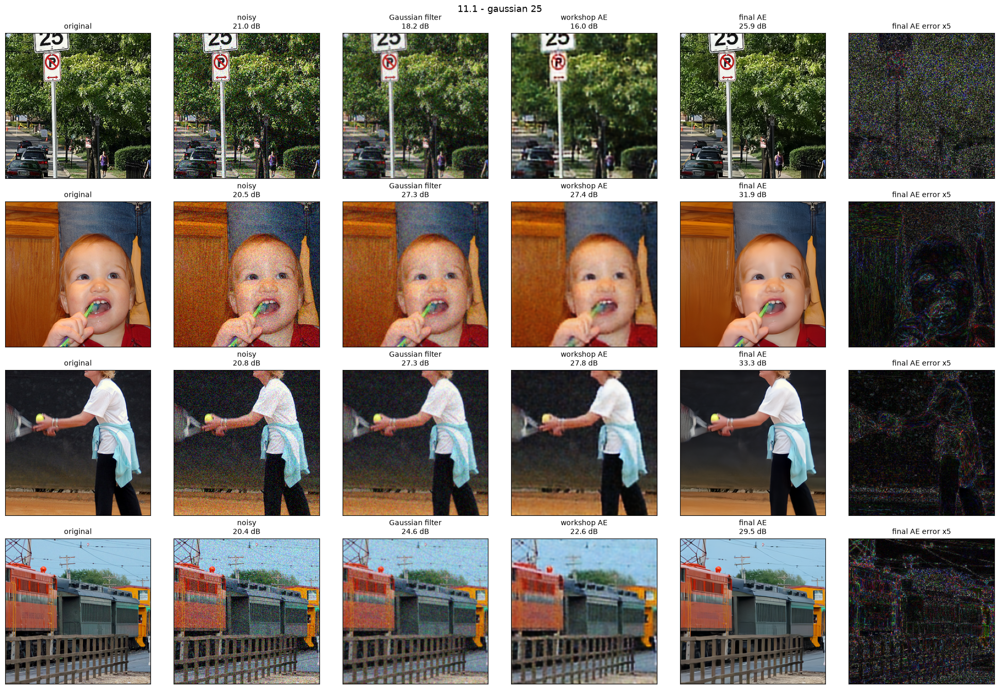

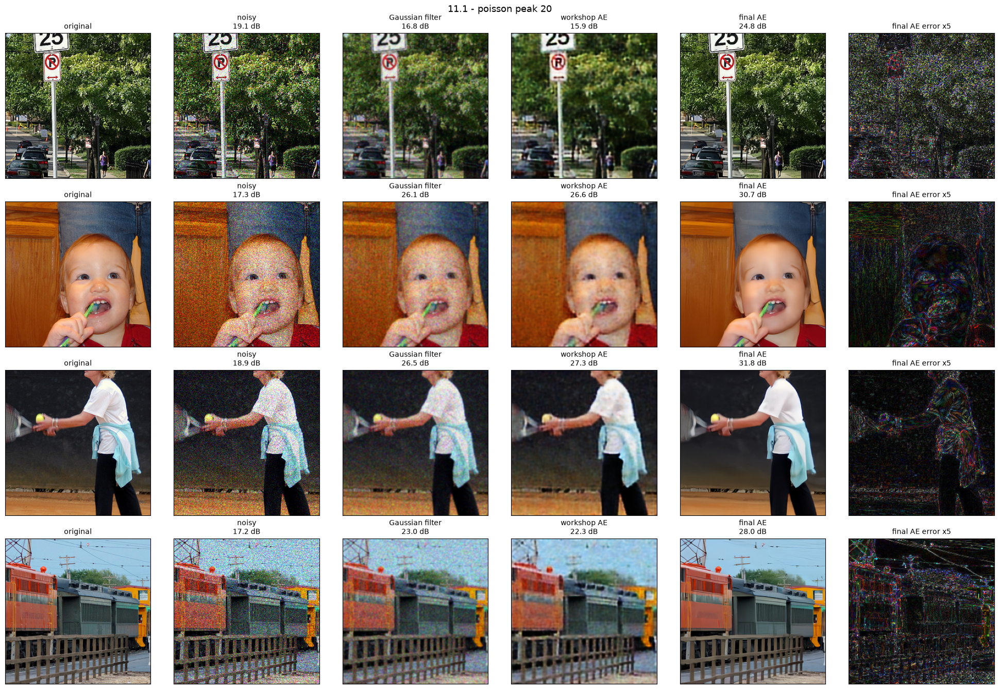

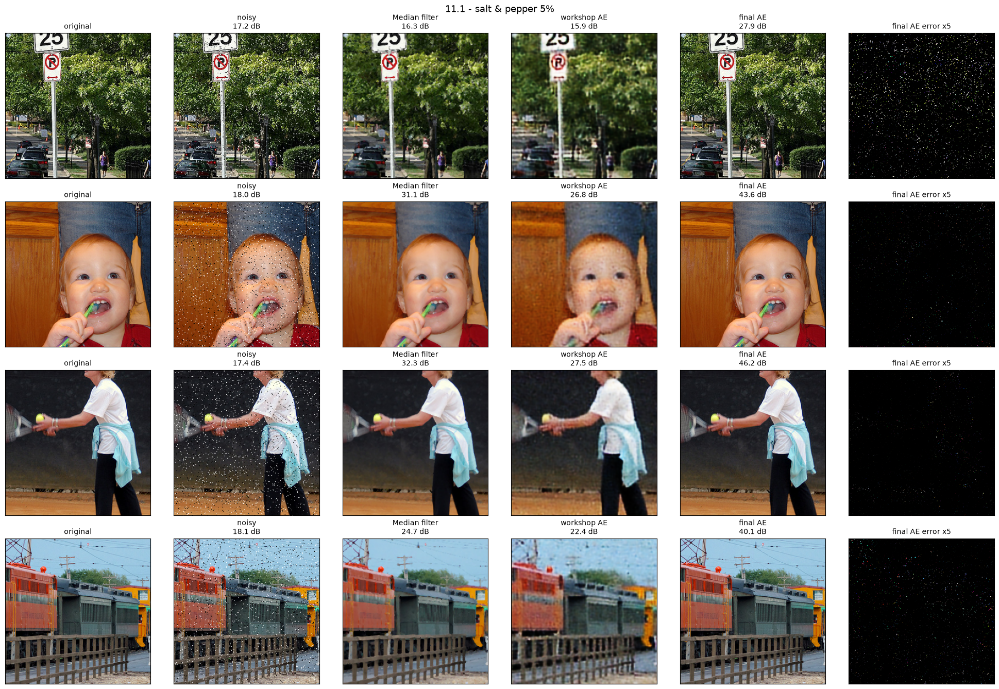

In [17]:
CASE_INDEX = list(np.random.default_rng(7).choice(len(test_u8), 4, replace=False))


def case_noisy(cond, idx, key=SEED + 900):
    kind, level = CONDITIONS[cond]
    clean = test_u8[idx] / 255.0
    return add_noise(tf.constant(clean, tf.float32), kind, level, seed=tf.constant([key, 0])).numpy(), clean.astype("float32")


def case_figure(cond):
    noisy, clean = case_noisy(cond, CASE_INDEX)
    filt = "Median filter" if cond.startswith("salt") else "Gaussian filter"
    outs = {"original": clean, "noisy": noisy, filt: METHODS[filt](noisy, cond), "workshop AE": METHODS["Workshop AE"](noisy, cond),
            "final AE": METHODS[FINAL](noisy, cond)}
    outs["final AE error x5"] = np.clip(np.abs(outs["final AE"] - clean) * 5, 0, 1)
    fig, axes = plt.subplots(len(clean), len(outs), figsize=(3.3 * len(outs), 3.4 * len(clean)))
    for r in range(len(clean)):
        for c, (name, imgs) in enumerate(outs.items()):
            ax = axes[r, c]; ax.imshow(np.clip(imgs[r], 0, 1)); ax.set_xticks([]); ax.set_yticks([])
            title = name if name in ("original", "final AE error x5") else \
                f"{name}\n{psnr_of(clean[r:r + 1], np.clip(imgs[r:r + 1], 0, 1).astype('float32'))[0]:.1f} dB"
            ax.set_title(title, fontsize=10)
    plt.suptitle(f"11.1 - {cond}", fontsize=13); plt.tight_layout(); plt.show()


case_figure("gaussian 25")
case_figure("poisson peak 20")
case_figure("salt & pepper 5%")

### 11.2 Zoom on the most detailed region
For two images, the 48 x 48 window with the highest density of edges in the clean image (Sobel magnitude, box-averaged) is enlarged with nearest-neighbour interpolation, for each method at Gaussian sigma = 25.

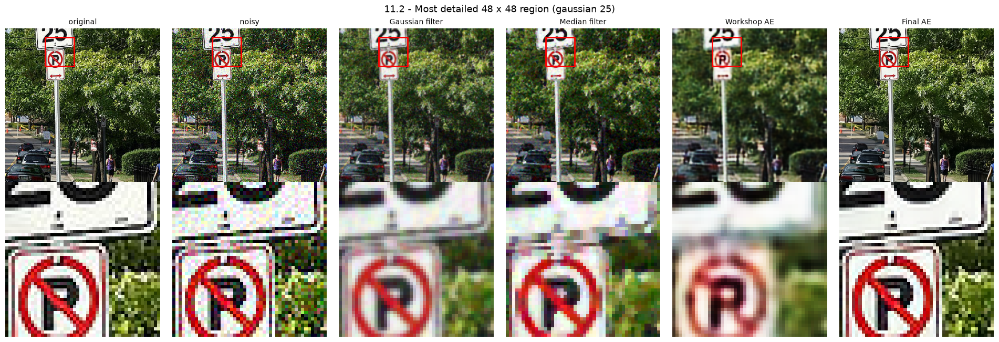

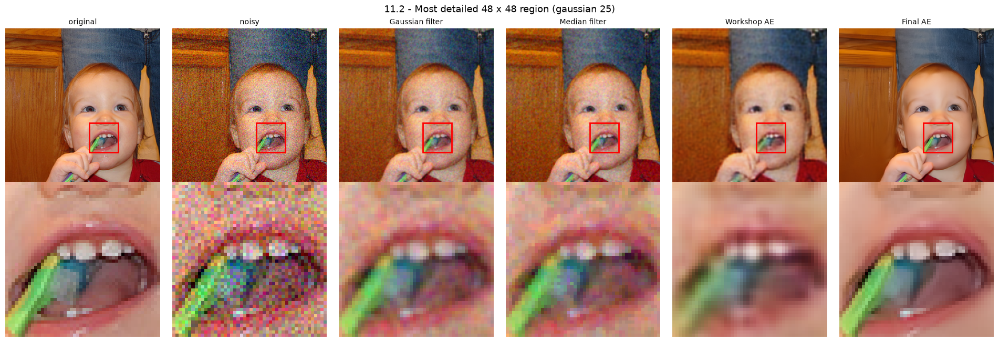

In [18]:
def zoom_figure(cond, idx, win=48):
    noisy, clean = case_noisy(cond, [idx])
    g = tf.norm(tf.image.sobel_edges(tf.image.rgb_to_grayscale(tf.constant(clean)))[..., 0, :], axis=-1)[..., None]
    density = tf.nn.avg_pool2d(g, win, 1, "VALID")[0, :, :, 0].numpy()
    y0, x0 = np.unravel_index(np.argmax(density), density.shape)
    panels = [("original", clean[0]), ("noisy", noisy[0])] + \
             [(m, np.clip(METHODS[m](noisy, cond)[0], 0, 1)) for m in ["Gaussian filter", "Median filter", "Workshop AE", FINAL]]
    fig, axes = plt.subplots(2, len(panels), figsize=(3.2 * len(panels), 6.6))
    for c, (name, img) in enumerate(panels):
        axes[0, c].imshow(img); axes[0, c].set_title(name, fontsize=10)
        axes[0, c].add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), win, win, fill=False, edgecolor="red", lw=2))
        axes[1, c].imshow(img[y0:y0 + win, x0:x0 + win], interpolation="nearest")
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle(f"11.2 - Most detailed 48 x 48 region ({cond})", fontsize=13); plt.tight_layout(); plt.show()


zoom_figure("gaussian 25", CASE_INDEX[0])
zoom_figure("gaussian 25", CASE_INDEX[1])

### 11.3 What exactly was removed?
For one image at sigma = 25, for the Gaussian filter and the final AE (signed maps x2 around grey):
* **noise added** = y - x (the ground truth of what should be removed);
* **removed** = y - f(y). Any visible scene structure in this map is signal removed together with the noise;
* **remaining error** = f(y) - x.

Over the test crops, we report the mean per-image Pearson correlation between "removed" and "noise added" (1 means exactly the noise and nothing else was removed).

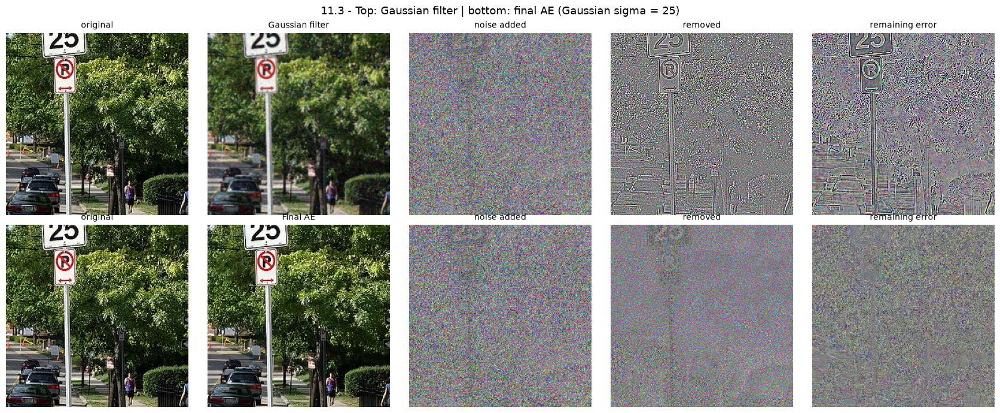

,mean correlation (removed vs noise added)
Gaussian filter,0.802
Median filter,0.783
Workshop AE,0.805
Final AE,0.942


In [19]:
cond = "gaussian 25"
noisy, clean = case_noisy(cond, [CASE_INDEX[0]])
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for r, name in enumerate(["Gaussian filter", FINAL]):
    out = np.clip(METHODS[name](noisy, cond), 0, 1)
    panels = [("original", clean[0]), (name, out[0]), ("noise added", (noisy[0] - clean[0]) * 2 + 0.5),
              ("removed", (noisy[0] - out[0]) * 2 + 0.5), ("remaining error", (out[0] - clean[0]) * 2 + 0.5)]
    for c, (t, img) in enumerate(panels):
        axes[r, c].imshow(np.clip(img, 0, 1)); axes[r, c].set_title(t, fontsize=10); axes[r, c].axis("off")
plt.suptitle("11.3 - Top: Gaussian filter | bottom: final AE (Gaussian sigma = 25)", fontsize=13); plt.tight_layout(); plt.show()


def removed_noise_correlation(out, noisy, clean):
    removed = (noisy - out).reshape(len(clean), -1); added = (noisy - clean).reshape(len(clean), -1)
    removed = removed - removed.mean(1, keepdims=True); added = added - added.mean(1, keepdims=True)
    return (removed * added).sum(1) / np.sqrt((removed ** 2).sum(1) * (added ** 2).sum(1))


corr = {m: [] for m in ["Gaussian filter", "Median filter", "Workshop AE", FINAL]}
for _, noisy_b, clean_b in noisy_blocks(test_u8, cond):
    for m in corr:
        corr[m].append(removed_noise_correlation(np.clip(METHODS[m](noisy_b, cond), 0, 1), noisy_b, clean_b))
display(pd.DataFrame({"mean correlation (removed vs noise added)": {m: round(float(np.concatenate(v).mean()), 3) for m, v in corr.items()}}))

### 11.4 How much detail is lost, and where?
Pixels of each clean crop are classified by the Sobel gradient magnitude of the clean image: the 20 % strongest are **edges / texture**, the 50 % weakest are **flat**. We report the mean absolute error on each class (grey levels /255) and their ratio. A denoiser that removes noise but loses detail has a low error on flat areas and a high one on edges.

**Fine detail kept** = median over images of E[(L * f(y))^2] / E[(L * x)^2], where L is the 3 x 3 Laplacian, which responds to the finest scales only. 100 % means as much fine-scale energy as the original; below means smoothing; above means residual noise or invented texture.

In [20]:
LAPLACIAN = tf.constant(np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)[:, :, None, None])


def fine_energy(x):
    return tf.reduce_mean(tf.square(tf.nn.conv2d(tf.image.rgb_to_grayscale(x), LAPLACIAN, 1, "VALID")), axis=[1, 2, 3]).numpy()


def detail_report(cond, n=500):
    acc = {m: {"edges": [], "flat": [], "kept": []} for m in METHODS}
    for _, noisy, clean in noisy_blocks(test_u8[:n], cond):
        g = tf.norm(tf.image.sobel_edges(tf.image.rgb_to_grayscale(tf.constant(clean)))[..., 0, :], axis=-1).numpy()
        g = g.reshape(len(clean), -1)
        hi = g >= np.percentile(g, 80, axis=1, keepdims=True)
        lo = g <= np.percentile(g, 50, axis=1, keepdims=True)
        ref = fine_energy(tf.constant(clean))
        for m, method in METHODS.items():
            out = np.clip(method(noisy, cond), 0, 1).astype("float32")
            err = np.abs(out - clean).mean(axis=3).reshape(len(clean), -1)
            acc[m]["edges"] += list((err * hi).sum(1) / hi.sum(1)); acc[m]["flat"] += list((err * lo).sum(1) / lo.sum(1))
            acc[m]["kept"] += list(fine_energy(tf.constant(out)) / ref)
    return pd.DataFrame({m: {"error on edges (/255)": 255 * np.mean(a["edges"]), "error on flat areas (/255)": 255 * np.mean(a["flat"]),
                             "edges / flat": np.mean(a["edges"]) / np.mean(a["flat"]),
                             "fine detail kept (%)": 100 * np.median(a["kept"])} for m, a in acc.items()}).T.round(2)


for cond in ["clean", "gaussian 25", "gaussian 50", "poisson peak 20"]:
    print(f"\n{cond} (first 500 test crops):")
    display(detail_report(cond))


clean (first 500 test crops):


,error on edges (/255),error on flat areas (/255),edges / flat,fine detail kept (%)
Noisy input,0.00,0.00,NaN,100.00
Gaussian filter,6.55,1.46,4.50,38.47
Median filter,10.78,3.53,3.06,24.46
Workshop AE,19.50,5.76,3.38,5.53
Final AE,0.03,0.01,2.01,99.99



gaussian 25 (first 500 test crops):


,error on edges (/255),error on flat areas (/255),edges / flat,fine detail kept (%)
Noisy input,19.02,18.38,1.04,328.60
Gaussian filter,16.27,8.50,1.91,15.82
Median filter,17.61,9.29,1.89,29.44
Workshop AE,20.20,6.85,2.95,5.22
Final AE,8.00,3.96,2.02,74.65



gaussian 50 (first 500 test crops):


,error on edges (/255),error on flat areas (/255),edges / flat,fine detail kept (%)
Noisy input,36.02,34.34,1.05,906.13
Gaussian filter,24.28,11.57,2.10,1.37
Median filter,24.88,11.48,2.17,14.08
Workshop AE,22.10,9.40,2.35,4.79
Final AE,11.99,5.19,2.31,55.35



poisson peak 20 (first 500 test crops):


,error on edges (/255),error on flat areas (/255),edges / flat,fine detail kept (%)
Noisy input,27.10,25.51,1.06,579.69
Gaussian filter,20.04,9.56,2.10,6.54
Median filter,23.48,9.84,2.39,15.13
Workshop AE,20.86,7.69,2.71,5.42
Final AE,9.75,4.40,2.22,66.07


### 11.5 When does the loss of detail change the content?
For the final AE at Gaussian sigma = 25 and 50, the test images whose encoder top-1 class differs from the clean image are counted and split into two groups: those whose noisy input had already changed class (information destroyed by the noise), and those whose noisy input still had the right class (the change was introduced by the denoiser). Examples of the second group are shown with the ImageNet class names.

Number of test crops (out of 1000) whose encoder top-1 class differs from the clean image:


,gaussian 25,gaussian 50,poisson peak 20
changed after noise only,463,633,563
changed after final AE,354,472,398
of which noisy input already changed,239,382,309
of which introduced by the denoiser,115,90,89
changed after workshop AE,607,741,676


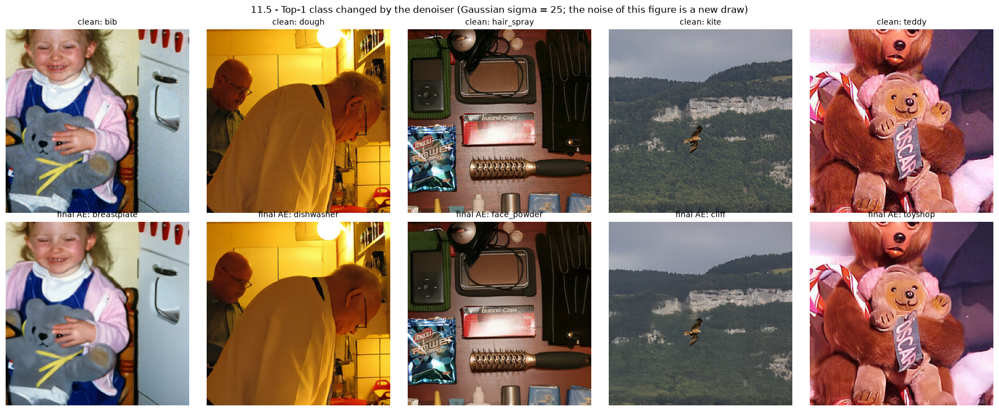

In [21]:
class_index = json.load(open(keras.utils.get_file(
    "imagenet_class_index.json", "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json")))
names = [class_index[str(k)][1] for k in range(1000)]

rows = {}
for cond in ["gaussian 25", "gaussian 50", "poisson peak 20"]:
    s = test_scores[test_scores.condition == cond].pivot_table(index="image", columns="method", values="same top-1")
    rows[cond] = {"changed after noise only": int((~s["Noisy input"].astype(bool)).sum()),
                  "changed after final AE": int((~s[FINAL].astype(bool)).sum()),
                  "  of which noisy input already changed": int((~s[FINAL].astype(bool) & ~s["Noisy input"].astype(bool)).sum()),
                  "  of which introduced by the denoiser": int((~s[FINAL].astype(bool) & s["Noisy input"].astype(bool)).sum()),
                  "changed after workshop AE": int((~s["Workshop AE"].astype(bool)).sum())}
print(f"Number of test crops (out of {N_TEST}) whose encoder top-1 class differs from the clean image:")
display(pd.DataFrame(rows))

cond = "gaussian 25"
s = test_scores[test_scores.condition == cond].pivot_table(index="image", columns="method", values="same top-1")
introduced = s.index[(~s[FINAL].astype(bool)) & s["Noisy input"].astype(bool)][:5].to_numpy()
if len(introduced):
    noisy_all = make_noisy(test_u8[introduced], cond, base_seed=SEED + 950)
    den = np.clip(METHODS[FINAL](noisy_all, cond), 0, 1)
    _, top_clean = encoder_outputs(test_u8[introduced] / 255.0)
    _, top_den = encoder_outputs(den)
    fig, axes = plt.subplots(2, len(introduced), figsize=(3.6 * len(introduced), 7.4), squeeze=False)
    for c in range(len(introduced)):
        axes[0, c].imshow(test_u8[introduced[c]]); axes[0, c].set_title(f"clean: {names[top_clean[c]]}", fontsize=10)
        axes[1, c].imshow(den[c]); axes[1, c].set_title(f"final AE: {names[top_den[c]]}", fontsize=10)
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle("11.5 - Top-1 class changed by the denoiser (Gaussian sigma = 25; the noise of this figure is a new draw)", fontsize=12)
    plt.tight_layout(); plt.show()

### 11.6 From light to strong noise (beyond the brief)
Gaussian sigma is swept from 0 to 100/255 on 300 test crops, beyond the training range (sigma <= 51/255). We report PSNR, fine detail kept and encoder feature cosine. At each sigma the Gaussian filter uses the best value of its grid, chosen on these same images, so it is an oracle upper bound for that filter.

*Why:* the noise level of a real scan is not known in advance, so behaviour outside the training range must be measured rather than assumed.

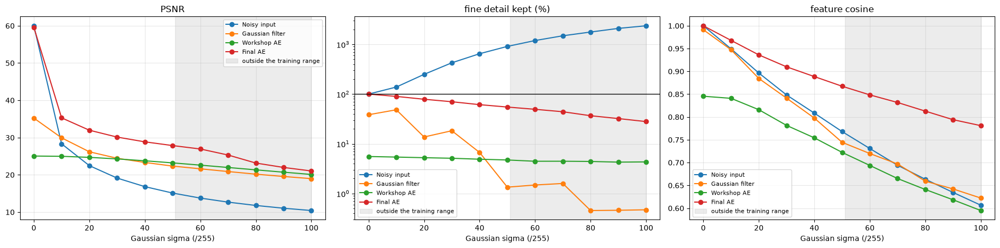

,sigma 0,sigma 10,sigma 20,sigma 30,sigma 40,sigma 50,sigma 60,sigma 70,sigma 80,sigma 90,sigma 100
Noisy input | PSNR,60.000,28.329,22.472,19.135,16.838,15.116,13.765,12.678,11.787,11.044,10.424
Noisy input | fine detail kept (%),100.000,138.742,249.450,426.430,648.939,910.530,1194.485,1489.691,1771.662,2096.916,2367.234
Noisy input | feature cosine,1.000,0.949,0.896,0.848,0.808,0.768,0.731,0.694,0.663,0.635,0.607
Gaussian filter | PSNR,35.231,29.932,26.190,24.452,23.324,22.353,21.620,20.887,20.182,19.563,18.982
Gaussian filter | fine detail kept (%),38.470,48.385,13.725,18.334,6.709,1.344,1.485,1.595,0.455,0.461,0.472
Gaussian filter | feature cosine,0.991,0.947,0.884,0.841,0.798,0.745,0.720,0.697,0.659,0.642,0.622
Workshop AE | PSNR,25.045,24.974,24.691,24.275,23.776,23.210,22.607,21.974,21.339,20.713,20.109
Workshop AE | fine detail kept (%),5.557,5.416,5.260,5.126,4.904,4.732,4.462,4.466,4.419,4.285,4.329
Workshop AE | feature cosine,0.845,0.841,0.816,0.782,0.754,0.722,0.694,0.665,0.641,0.618,0.595
Final AE | PSNR,59.597,35.291,31.979,30.133,28.854,27.858,26.939,25.318,23.163,21.986,21.038


In [22]:
sweep_u8 = test_u8[:300]
sweep_clean = sweep_u8 / 255.0
sigmas = np.arange(0, 101, 10)
ref_feat, _ = encoder_outputs(sweep_clean.astype("float32"))
ref_fine = fine_energy(tf.constant(sweep_clean, tf.float32))
curves = {m: {"PSNR": [], "fine detail kept (%)": [], "feature cosine": []} for m in ["Noisy input", "Gaussian filter", "Workshop AE", FINAL]}
for j, s in enumerate(sigmas):
    noisy = np.concatenate([add_noise(tf.constant(sweep_clean[i:i + 100], tf.float32), "gaussian", s / 255, seed=tf.constant([SEED + 500 + j, i])).numpy()
                            for i in range(0, len(sweep_clean), 100)])
    for m in curves:
        if m == "Gaussian filter":
            outs = [np.clip(in_chunks(lambda b: gaussian_filter(b, p), noisy), 0, 1) for p in FILTER_GRID["Gaussian filter"][1]]
            out = max(outs, key=lambda o: psnr_of(sweep_clean, o).mean())
        else:
            out = np.clip(METHODS[m](noisy, None), 0, 1)
        out = out.astype("float32")
        feat, _ = encoder_outputs(out)
        curves[m]["PSNR"].append(float(psnr_of(sweep_clean, out).mean()))
        curves[m]["fine detail kept (%)"].append(float(100 * np.median(fine_energy(tf.constant(out)) / ref_fine)))
        curves[m]["feature cosine"].append(float(np.mean(np.sum(feat * ref_feat, axis=1))))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for k, key in enumerate(["PSNR", "fine detail kept (%)", "feature cosine"]):
    for m, c in curves.items():
        ax[k].plot(sigmas, c[key], "o-", label=m)
    ax[k].axvspan(51, 100, color="grey", alpha=0.15, label="outside the training range")
    ax[k].set_xlabel("Gaussian sigma (/255)"); ax[k].set_title(key); ax[k].grid(alpha=0.3); ax[k].legend(fontsize=8)
ax[1].set_yscale("log"); ax[1].axhline(100, color="black", lw=1)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"{m} | {k}": np.round(np.array(v, dtype=float), 3) for m, c in curves.items() for k, v in c.items()},
                     index=[f"sigma {s}" for s in sigmas]).T)

### 11.7 Case study conclusion

**The noise disappears.** At sigma = 25, PSNR rises from 20.6 to 30.9 dB, and the error on flat regions falls from 18.4 to 4.0 grey levels. The removed component correlates at 0.94 with the true noise, against about 0.80 for the baselines, so the network removes mostly noise.

**Detail is lost, measurably.** The residual error on edges and texture is twice that on flat regions (8.0 versus 4.0 grey levels). The fine-scale energy kept falls from 99.99 % on clean inputs to 75 % at sigma = 25 and 55 % at sigma = 50. As the noise grows, the posterior over the clean image widens, and the MAE estimate (a median) becomes smoother. The baselines lose far more: the Gaussian filter keeps 16 % of the fine-scale energy at sigma = 25, and the workshop AE about 5.5 %, even on clean inputs.

**Content.** At sigma = 25, the denoiser corrects 224 encoder-class changes caused by the noise but introduces 115. It typically does so by smoothing fine texture (fur, foliage) into a plausible but different surface. The net effect is positive.

**Noise strength.** The final AE remains the best method over the whole sweep, including beyond the training range (21.0 dB at sigma = 100/255, against 20.1 dB for the workshop AE and 19.0 dB for the Gaussian filter). It degrades smoothly rather than failing.

## Section 12 - Saved model, full-resolution inference and real noisy photographs

`MODEL_PATH` holds the weights with the lowest validation loss (epoch 58 of 60), the ones evaluated in Sections 9 to 11; the reloaded file reproduces the Section 10 score below. `denoise_image` handles any image size in 256 x 256 tiles, each given 64 pixels of surrounding context, which bounds memory on large scans. Away from the image border, the tiled output differs from a single pass by 0.1 grey level on average (at most 2). At the border itself, the single pass zero-pads while the tiles reflect the image. `denoise_folder` writes lossless PNGs. Demonstrations follow on full-resolution test photographs with synthetic noise, and on the test photographs with the highest estimated real noise.

In [23]:
reloaded = keras.models.load_model(MODEL_PATH, compile=False)
saved_psnr = np.concatenate([psnr_of(clean, np.clip(reloaded.predict(noisy, batch_size=16, verbose=0), 0, 1))
                             for _, noisy, clean in noisy_blocks(test_u8, "gaussian 25")])
print(f"{MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB) | saved checkpoint, test crops, Gaussian sigma = 25: "
      f"mean PSNR {saved_psnr.mean():.2f} dB")
TILE, MARGIN = 256, 64      # tiles bound GPU memory on large scans; the margin gives each tile its surrounding context


def denoise_image(img):
    # img: uint8 (H, W, 3) or (H, W) -> denoised uint8 (H, W, 3), same size; processed in overlapping tiles
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    x = img[..., :3].astype("float32") / 255.0
    h, w = x.shape[:2]
    H, W = h + -h % TILE, w + -w % TILE
    x = np.pad(x, ((MARGIN, MARGIN + H - h), (MARGIN, MARGIN + W - w), (0, 0)), mode="reflect")
    out = np.empty((H, W, 3), np.float32)
    for i in range(0, H, TILE):
        for j in range(0, W, TILE):
            tile = x[None, i:i + TILE + 2 * MARGIN, j:j + TILE + 2 * MARGIN]
            out[i:i + TILE, j:j + TILE] = reloaded(tile, training=False).numpy()[0, MARGIN:MARGIN + TILE, MARGIN:MARGIN + TILE]
    return np.round(np.clip(out[:h, :w], 0.0, 1.0) * 255).astype(np.uint8)


# tiling check: a 480 x 480 noisy crop (4 tiles) denoised in tiles and in one pass
probe_img = decode(test_paths[40]).numpy()[:480, :480]
probe_noisy = np.round(add_noise(tf.constant(probe_img[None]), "gaussian", 25 / 255, seed=tf.constant([SEED, 1])).numpy()[0] * 255).astype(np.uint8)
whole = np.round(np.clip(reloaded(probe_noisy[None] / 255.0, training=False).numpy()[0], 0, 1) * 255)
diff = np.abs(denoise_image(probe_noisy).astype(float) - whole).max(axis=-1)
inner = diff[16:-16, 16:-16]          # the one pass zero-pads at the image border, the tiles reflect
print(f"tiled vs one pass ({probe_noisy.shape[1]} x {probe_noisy.shape[0]}, grey levels): mean |diff| {diff.mean():.3f}, max {diff.max():.0f}; "
      f"excluding the 16-pixel image border: mean {inner.mean():.3f}, max {inner.max():.0f}")


def denoise_folder(input_dir, output_dir):
    input_dir, output_dir = Path(input_dir), Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    files = sorted(p for p in input_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"})
    for p in files:
        Image.fromarray(denoise_image(np.asarray(Image.open(p).convert("RGB")))).save(output_dir / (p.stem + ".png"))
    return files

denoiser_coco.keras (131.0 MB) | saved checkpoint, test crops, Gaussian sigma = 25: mean PSNR 30.92 dB


tiled vs one pass (480 x 360, grey levels): mean |diff| 0.294, max 26; excluding the 16-pixel image border: mean 0.111, max 2


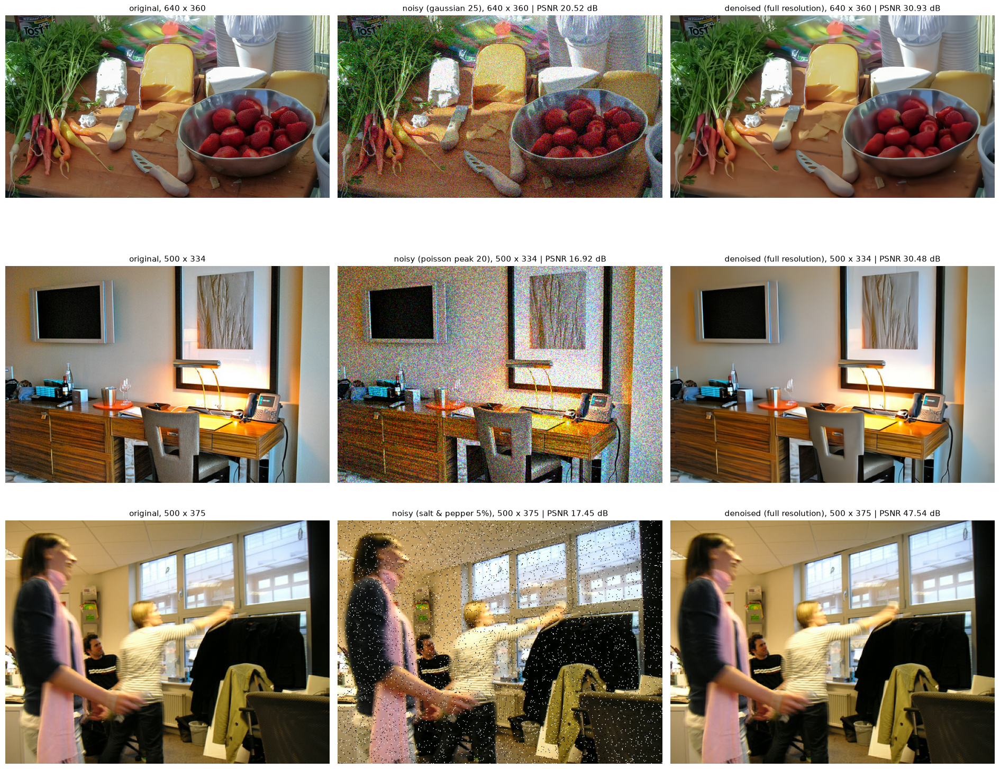

In [24]:
demo_in, demo_out = Path("demo/noisy"), Path("demo/denoised")
demo_in.mkdir(parents=True, exist_ok=True)
demo = [(test_paths[40], "gaussian 25"), (test_paths[41], "poisson peak 20"), (test_paths[42], "salt & pepper 5%")]
originals = {}
for k, (path, cond) in enumerate(demo):
    clean = decode(path).numpy()[None]
    kind, level = CONDITIONS[cond]
    noisy = add_noise(tf.constant(clean), kind, level, seed=tf.constant([SEED + 99, k])).numpy()[0]
    name = f"{k}_{Path(path).stem}"
    Image.fromarray(np.round(noisy * 255).astype(np.uint8)).save(demo_in / f"{name}.png")
    originals[name] = (clean[0], cond)
denoise_folder(demo_in, demo_out)

fig, axes = plt.subplots(len(originals), 3, figsize=(19, 5.2 * len(originals)))
for r, (name, (clean, cond)) in enumerate(originals.items()):
    noisy = np.asarray(Image.open(demo_in / f"{name}.png")) / 255.0
    den = np.asarray(Image.open(demo_out / f"{name}.png")) / 255.0
    for c, (t, img) in enumerate([("original", clean), (f"noisy ({cond})", noisy), ("denoised (full resolution)", den)]):
        p = "" if c == 0 else f" | PSNR {psnr_of(clean[None].astype('float32'), img[None].astype('float32'))[0]:.2f} dB"
        axes[r, c].imshow(img); axes[r, c].set_title(f"{t}, {img.shape[1]} x {img.shape[0]}{p}", fontsize=11); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

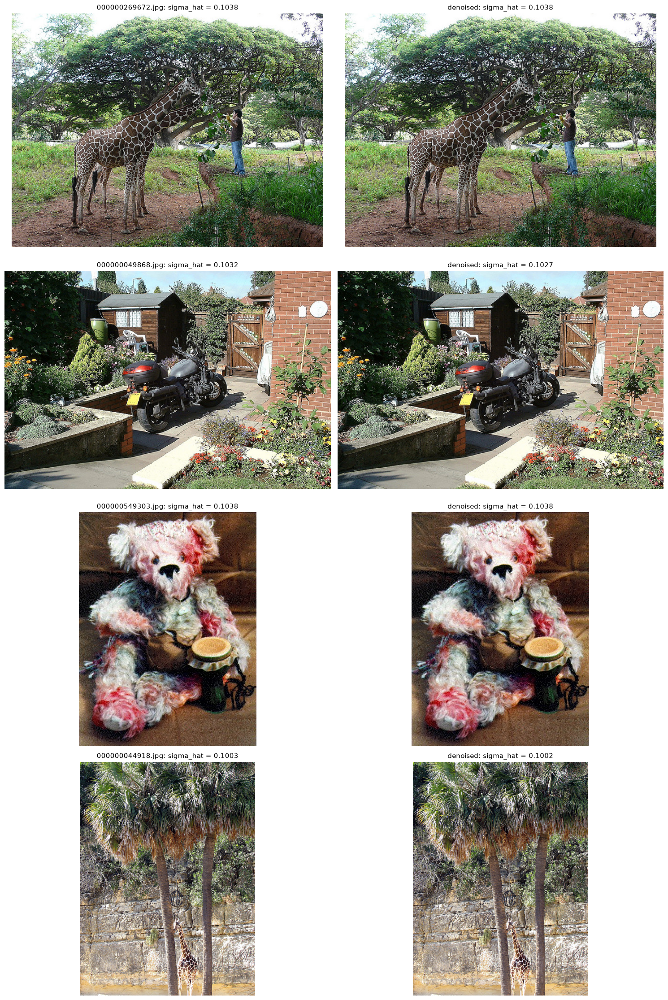

,size,sigma_hat before,sigma_hat after
file,,,
000000269672.jpg,640 x 480,0.1038,0.1038
000000049868.jpg,640 x 427,0.1032,0.1027
000000549303.jpg,377 x 496,0.1038,0.1038
000000044918.jpg,480 x 640,0.1003,0.1002


In [25]:
# real noise: the test photographs with the highest Immerkaer estimate in Section 3 (no clean reference exists)
noisiest = probe[probe.split == "test"].sort_values("sigma", ascending=False).head(4)
rows = []
fig, axes = plt.subplots(len(noisiest), 2, figsize=(15, 5.6 * len(noisiest)))
for r, p in enumerate(noisiest.path):
    img = np.asarray(Image.open(p).convert("RGB"))
    den = denoise_image(img)
    before = float(immerkaer_sigma(tf.constant(img / 255.0, tf.float32))); after = float(immerkaer_sigma(tf.constant(den / 255.0, tf.float32)))
    rows.append({"file": Path(p).name, "size": f"{img.shape[1]} x {img.shape[0]}", "sigma_hat before": before, "sigma_hat after": after})
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"{Path(p).name}: sigma_hat = {before:.4f}", fontsize=11)
    axes[r, 1].imshow(den); axes[r, 1].set_title(f"denoised: sigma_hat = {after:.4f}", fontsize=11)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("file").round(4))

**Reading.** The photographs with the highest estimate are not noisy but heavily textured (foliage, fur, palm leaves), the over-reading anticipated in Section 3. The denoiser leaves them essentially unchanged (sigma_hat changes by at most 0.0005), so it does not mistake natural texture for noise. Evaluating on real noise requires real noisy/clean pairs (Section 14).

## Section 13 - Fine-tuning on correlated and compressed noise (the delivered model)

*Why:* when the whole chain (D1 → D2 → D3) was tested on real files, a visibly noisy photograph came out of the Section 9 model unchanged. Its noise was almost identical in the three colour channels (correlation 0.97) and the file was JPEG-compressed. Section 5 draws the noise independently per channel and never compresses it, so these inputs lay outside the training distribution. Measured on validation crops, the first-stage model leaves such inputs where they are: 20.7 dB in, 20.7 dB out for Gaussian sigma = 25 shared by the channels.

**Method.** The Section 9 model is fine-tuned, not retrained, on the same pipeline (128 x 128 crops of `train2017`, MAE, mixed precision). Two changes are made to the noise mixture of Section 5:
* Gaussian and speckle noise get a random correlation rho between channels, n = rho n_shared + sqrt(1 - rho^2) n_channel, with rho = clip(U(-0.5, 1.5), 0, 1). This makes the noise independent for a quarter of the crops, fully shared for a quarter, and partly shared for the rest;
* half of the noisy inputs are then JPEG-compressed at a quality drawn in [30, 95].

The target remains the clean crop, so the network also learns to remove compression artefacts. The learning rate peaks at a quarter of the original (5e-5, cosine schedule) for 15 epochs, and the weights with the lowest validation loss are kept. Both models are compared on the 500 `score` crops of validation. The six original conditions test what is kept, and six new conditions test what is gained.

In [ ]:
def channel_noise(shape):
    # standard normal noise whose correlation between the three channels is rho: 1/4 independent, 1/4 shared, 1/2 between
    rho = tf.clip_by_value(tf.random.uniform([], -0.5, 1.5), 0.0, 1.0)
    shared = tf.random.normal(tf.concat([shape[:2], [1]], 0))
    return rho * shared + tf.sqrt(1.0 - rho * rho) * tf.random.normal(shape)


def extended_noisy_example(clean):
    # the Section 5 mixture with channel-correlated Gaussian and speckle noise, then JPEG compression with probability P_JPEG
    shape, pick = tf.shape(clean), tf.random.uniform([])
    gauss = lambda: clean + tf.random.uniform([], 0.0, 0.2) * channel_noise(shape)
    sp = lambda: (lambda u, lv: tf.where(u < lv / 2, 0.0, tf.where(u > 1 - lv / 2, 1.0, clean)))(
        tf.random.uniform(tf.concat([shape[:2], [1]], 0)), tf.random.uniform([], 0.0, 0.1))
    speck = lambda: clean + clean * tf.random.uniform([], 0.0, 0.4) * channel_noise(shape)
    poisson = lambda: (lambda peak: tf.random.poisson([], clean * peak) / peak)(tf.exp(tf.random.uniform([], math.log(5.0), math.log(100.0))))
    noisy = tf.case([(pick < 0.10, lambda: clean), (pick < 0.325, gauss), (pick < 0.55, sp), (pick < 0.775, speck)], default=poisson)
    noisy = tf.clip_by_value(noisy, 0.0, 1.0)
    q = tf.random.uniform([], JPEG_Q[0], JPEG_Q[1] + 1, dtype=tf.int32)
    noisy = tf.cond(tf.random.uniform([]) < P_JPEG, lambda: tf.image.adjust_jpeg_quality(noisy, q), lambda: noisy)
    return tf.ensure_shape(noisy, clean.shape), clean


def extended_train_example(path):
    return extended_noisy_example(tf.image.random_flip_left_right(tf.image.random_crop(decode(path), (PATCH, PATCH, 3))))


# evaluation: the original conditions plus the new ones, with numpy noise and PIL JPEG at fixed seeds
def jpeg(x, q):
    b = io.BytesIO(); Image.fromarray(np.round(x * 255).astype(np.uint8)).save(b, "JPEG", quality=q)
    return np.asarray(Image.open(b), np.float32) / 255


def corrupt(clean, cond, rng):
    kind, level, shared, q = cond
    shape = clean.shape[:2] + (1,) if shared else clean.shape
    if kind == "none":
        x = clean
    elif kind == "gaussian":
        x = clean + level * rng.standard_normal(shape)
    elif kind == "speckle":
        x = clean + clean * level * rng.standard_normal(shape)
    elif kind == "salt_pepper":
        u = rng.random(clean.shape[:2] + (1,)); x = np.where(u < level / 2, 0.0, np.where(u > 1 - level / 2, 1.0, clean))
    elif kind == "poisson":
        x = rng.poisson(clean * level) / level
    x = np.clip(x, 0, 1).astype(np.float32)
    return jpeg(x, q) if q else x


EXTENDED_CONDITIONS = {   # name: (kind, level, noise shared by the three channels, JPEG quality or 0)
    "clean":                           ("none", 0, False, 0),
    "gaussian 25":                     ("gaussian", 25 / 255, False, 0),
    "gaussian 50":                     ("gaussian", 50 / 255, False, 0),
    "salt & pepper 5%":                ("salt_pepper", 0.05, False, 0),
    "speckle 0.2":                     ("speckle", 0.2, False, 0),
    "poisson peak 20":                 ("poisson", 20.0, False, 0),
    "NEW gaussian 25, shared":         ("gaussian", 25 / 255, True, 0),
    "NEW gaussian 50, shared":         ("gaussian", 50 / 255, True, 0),
    "NEW clean, JPEG 75":              ("none", 0, False, 75),
    "NEW gaussian 25, JPEG 75":        ("gaussian", 25 / 255, False, 75),
    "NEW gaussian 25 shared, JPEG 75": ("gaussian", 25 / 255, True, 75),
    "NEW gaussian 50 shared, JPEG 75": ("gaussian", 50 / 255, True, 75),
}


def evaluate_extended(models, clean_u8):
    clean, rows = clean_u8.astype(np.float32) / 255, {}
    mean_psnr = lambda y: float(np.mean([10 * np.log10(1 / max(np.mean((a - b) ** 2), 1e-6)) for a, b in zip(y, clean)]))
    for c, (name, cond) in enumerate(EXTENDED_CONDITIONS.items()):
        rng = np.random.default_rng([SEED, c])
        noisy = np.stack([corrupt(x, cond, rng) for x in clean])
        rows[name] = {"noisy": mean_psnr(noisy)}
        for mname, m in models.items():
            rows[name][mname] = mean_psnr(np.clip(m.predict(noisy, batch_size=16, verbose=0), 0, 1))
    return rows


if FINAL_PATH.exists() and FT_RESULTS_PATH.exists():
    final = keras.models.load_model(FINAL_PATH, compile=False)
    ft_results = json.load(open(FT_RESULTS_PATH))
    print(f"Fine-tuned model reloaded from {FINAL_PATH} ({final.count_params():,} weights)")
else:
    keras.utils.set_random_seed(SEED)
    ft_train_ds = (tf.data.Dataset.from_tensor_slices(paths["train"])
                   .shuffle(len(paths["train"]), seed=SEED, reshuffle_each_iteration=True)
                   .map(extended_train_example, num_parallel_calls=PARALLEL_CALLS)
                   .batch(BATCH_SIZE, drop_remainder=True).repeat().prefetch(2))
    tf.random.set_seed(SEED + 1)                                    # the monitor noise is drawn once, then fixed
    ft_val_noisy = np.stack([extended_noisy_example(tf.constant(c))[0].numpy() for c in val_clean])

    keras.mixed_precision.set_global_policy("mixed_float16")
    model = build_resunet()
    keras.mixed_precision.set_global_policy("float32")
    model.set_weights(denoiser.get_weights())                      # starts from the Section 9 model
    schedule = keras.optimizers.schedules.CosineDecay(FT_LEARNING_RATE, decay_steps=FT_EPOCHS * STEPS_PER_EPOCH, alpha=0.01)
    model.compile(optimizer=keras.optimizers.Adam(schedule), loss="mae", metrics=[psnr], jit_compile=True)
    checkpoint = str(CACHE_DIR / "finetune.weights.h5")
    history = model.fit(ft_train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=FT_EPOCHS,
                        validation_data=(ft_val_noisy, val_clean), validation_batch_size=16, verbose=2,
                        callbacks=[keras.callbacks.ModelCheckpoint(checkpoint, monitor="val_loss", save_best_only=True,
                                                                   save_weights_only=True)]).history
    model.load_weights(checkpoint)
    final = build_resunet()                                        # float32 copy, as in Section 9
    final.set_weights(model.get_weights())
    final.save(FINAL_PATH)
    ft_results = {"history": history, "scores": evaluate_extended({"v1": denoiser, "v2": final}, val_u8["score"]),
                  "lr": FT_LEARNING_RATE, "epochs": FT_EPOCHS, "p_jpeg": P_JPEG, "jpeg_q": list(JPEG_Q)}
    json.dump(ft_results, open(FT_RESULTS_PATH, "w"), indent=1)

reloaded = final          # denoise_image and denoise_folder (Section 12) now use the delivered model

Mean PSNR (dB) on the 500 validation score crops


,noisy input,Section 9 model,fine-tuned,gain (dB)
clean,60.00,59.53,56.44,-3.09
gaussian 25,20.67,30.64,30.49,-0.15
gaussian 50,15.17,27.50,27.36,-0.14
salt & pepper 5%,17.81,40.53,39.81,-0.72
speckle 0.2,20.94,31.58,31.40,-0.18
poisson peak 20,17.55,29.13,29.04,-0.09
"NEW gaussian 25, shared",20.66,20.68,28.52,7.84
"NEW gaussian 50, shared",15.16,15.30,25.46,10.16
"NEW clean, JPEG 75",31.34,31.34,32.34,0.99
"NEW gaussian 25, JPEG 75",22.80,22.80,29.19,6.39


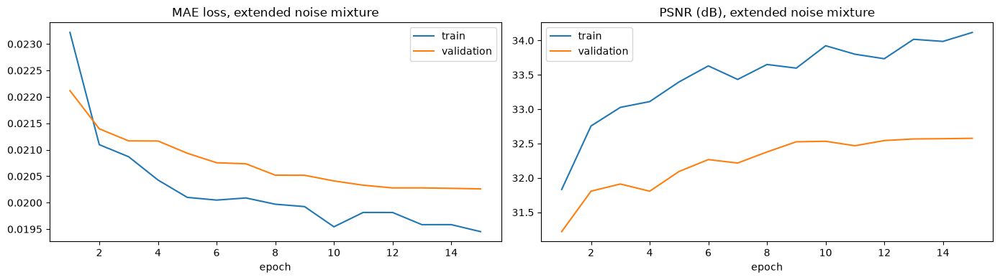

In [ ]:
scores = pd.DataFrame(ft_results["scores"]).T.rename(columns={"noisy": "noisy input", "v1": "Section 9 model", "v2": "fine-tuned"})
scores["gain (dB)"] = scores["fine-tuned"] - scores["Section 9 model"]
print("Mean PSNR (dB) on the 500 validation score crops")
display(scores.round(2))

h = ft_results["history"]
epochs = np.arange(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(epochs, h["loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
ax[0].set_title("MAE loss, extended noise mixture"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(epochs, h["psnr"], label="train"); ax[1].plot(epochs, h["val_psnr"], label="validation")
ax[1].set_title("PSNR (dB), extended noise mixture"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading.**
* **New conditions: large gains.** With noise shared by the channels, the fine-tuned model reaches 28.5 dB at sigma = 25 and 25.5 dB at sigma = 50, where the first stage left the input unchanged (+7.8 and +10.2 dB). With JPEG compression on top, the gains are similar: +7.9 and +10.1 dB. Per-channel noise followed by JPEG gains +6.4 dB.
* **JPEG artefacts.** A clean JPEG at quality 75 also improves (+1.0 dB), because the target was always the uncompressed crop.
* **Original conditions: small losses.** They lose between 0.09 and 0.72 dB (salt and pepper loses the most), the price of covering a wider distribution with the same capacity.
* **Clean inputs.** These fall from 59.5 to 56.4 dB, a root-mean-square change of 0.4 grey level. Extension E2 still holds: clean photographs pass through visually unchanged.

The fine-tuned model is the one delivered, `denoiser_coco_v2.keras`, and the one used by the test website (`website/pipeline.py`).

## Section 14 - Limits and possible improvements

* **Synthetic noise.** Section 13 adds noise correlated across the colour channels and JPEG compression, but real scanner noise is also spatially correlated and mixed with scanning artefacts. Real noisy/clean pairs (fast and careful scans of the same documents) would allow both fine-tuning and a true evaluation.
* **Imperfect targets.** COCO images carry their own noise and compression. A Noise2Noise-type objective would remove the need for clean targets.
* **Detail loss under strong noise.** At sigma = 50, 55 % of the fine-scale energy is kept. A perceptual or feature-space loss would trade some PSNR for texture.
* **Content changes.** The denoiser changes the encoder class of 11.5 % of images at sigma = 25. Fine-tuning with a loss on the captioning encoder's features would target this directly.
* **Blur is not handled.** Adding defocus and motion blur to the degradations would require no change to the architecture.
* **Capacity and inference.** The model converged under its schedule (best epoch 58 of 60). In the pilots, going from 2 to 4 residual blocks per level still gained 0.56 dB, so a deeper model would likely gain more, at a proportional cost. Averaging the outputs for the image and its mirror image adds 0.06 dB on validation for twice the inference cost, and was not kept.

The first two require data COCO does not provide (real noisy/clean pairs or repeated captures); the others require retraining and are left for future work. As well as these changes are outside the scope of this deliverable.

## Section 15 - Conclusion

We deliver a blind denoising autoencoder for photographs of any size: a 3-level U-Net built from residual blocks, with a residual output, an MAE loss and 32.7 M weights, trained from scratch on COCO 2017. On 1,000 test images it reaches 31.95 dB mean PSNR over eight noise conditions, +14.0 dB over the noisy input and +8.3 dB over the workshop autoencoder. It leaves clean images unchanged (59.6 dB), so it can run on every photograph without first detecting noise.

The delivered model is this network fine-tuned on noise shared across the colour channels and on JPEG-compressed noise (Section 13). This gains 6.4 to 10.2 dB on those inputs, which the first stage left untouched, for a loss of at most 0.7 dB on the original conditions.

In bias-variance terms, the workshop model was bias-limited: its bottleneck could not carry photographic detail. Skip connections, the residual parametrisation and residual blocks removed that limit step by step (+2.9, +1.5 and +1.1 dB at equal budget). Variance was not an issue, given fresh noise at every step and the agreement between validation and test.

The case study shows the expected trade-off. Noise is removed almost completely from flat regions, while fine texture is partly lost, increasingly with the noise strength: 25 % of the fine-scale energy is lost at sigma = 25, and 45 % at sigma = 50.

For Deliverable 3 (D1, then this denoiser, then a CNN encoder with an RNN decoder), the encoder-feature agreement measured here is the link between the two deliverables. The direct test is to caption the same noisy photographs with and without the denoiser.